# DEV Project – Milestone 1
## Notebook 01: Data Loading, Cleaning & Integration

**Course:** Data Engineering and Visualization – Winter 2026

**Team**
| Name | ID |
|---|---|
| Youssef Ahmed | 16009528 |
| Hana Ahmed | 16003196 |
| Mostafa Abuelabbas | 16001166 |
| Ziad Moharam | 16009510 |
| Hazem Ahmed | 16005924 |

**Datasets**
| Domain | Dataset | ID | Link |
|---|---|---|---|
| Housing & Development | Affordable Housing Production by Building (H2) | `hg8x-zxpr` | https://data.cityofnewyork.us/d/hg8x-zxpr |
| Transportation | Motor Vehicle Collisions – Crashes (T4) | `h9gi-nx95` | https://data.cityofnewyork.us/d/h9gi-nx95 |

**Theme – "Who pays for the city's growth?"**
We investigate whether NYC's new affordable housing, especially units for the lowest-income households, is being built in areas with more dangerous streets, and how crash patterns near new developments change over time.

## 🔗 Project Links

| | Link |
|---|---|
| 🌐 **Live website** | https://nyc-dev-dashboard.onrender.com |
| 💻 **GitHub repository** | https://github.com/ZiadMoharam6/nyc-dev-dashboard |
| 🏠 **Housing dataset (H2)** | [Affordable Housing Production by Building](https://data.cityofnewyork.us/Housing-Development/Affordable-Housing-Production-by-Building/hg8x-zxpr) |
| 🚗 **Transport dataset (T4)** | [Motor Vehicle Collisions – Crashes](https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-Crashes/h9gi-nx95) |

> The website runs on Render's free tier, which sleeps after inactivity. **The first visit may take ~50 seconds to load.**



---



---



## 1. Environment Setup – Mounting Google Drive

Colab's local storage is **temporary**: all files are deleted when the runtime disconnects.
We therefore mount Google Drive and store every dataset and intermediate output in the shared project folder `DEV_PROJECT/data/`, so that:
- work is not lost between sessions, and
- all team members read and write the same files.

`PROJECT_DIR` and `DATA_DIR` are defined once here and reused throughout the notebook.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/DEV_PROJECT/'
DATA_DIR = PROJECT_DIR + 'data/'
print(os.listdir(PROJECT_DIR))

Mounted at /content/drive
['data', '01_data_loading_and_overview.ipynb']




---



---



## 2. Data Extraction (the *Extract* step of ETL)

Both datasets are pulled directly from the **NYC Open Data SODA API**, which keeps the notebook reproducible: anyone who reruns it gets the data from the original source.

**Design decisions**
- `load_nyc_dataset()` is a reusable function, so both datasets are loaded the same way.
- `$limit` is set explicitly, because the API returns only **1,000 rows** by default.
- `$order=:id` gives a **stable row order**, so any sample we take is repeatable.
- `where` allows filtering on the server, so we never download more data than we need.

**Loading strategy**
| Dataset | Approach | Reason |
|---|---|---|
| Affordable Housing (H2) | Load **everything** | Small (thousands of rows), so no sampling needed |
| Crashes (T4) | **5,000-row preview** for now | Millions of rows; downloading everything could crash the notebook. The preview is used only to inspect the columns. A justified sample is chosen in Section 3. |

In [ ]:
import pandas as pd
from urllib.parse import urlencode

# Dataset IDs from NYC Open Data (found in each dataset's URL)
HOUSING_ID = 'hg8x-zxpr'    # H2: Affordable Housing Production by Building
TRANSPORT_ID = 'h9gi-nx95'  # T4: Motor Vehicle Collisions - Crashes

API_URL = 'https://data.cityofnewyork.us/resource/{}.csv'

def load_nyc_dataset(dataset_id, limit=1_000_000, where=None):
    """Download a dataset from the NYC Open Data API (SoQL).
    The API returns only 1,000 rows by default, so $limit must be set explicitly.
    `where` optionally filters rows on the server before downloading."""
    params = {'$limit': limit, '$order': ':id'}   # ':id' = stable order -> repeatable sample
    if where:
        params['$where'] = where
    url = API_URL.format(dataset_id) + '?' + urlencode(params)
    return pd.read_csv(url, low_memory=False)

# Housing: small dataset -> load everything
df_housing = load_nyc_dataset(HOUSING_ID)

# Transport: huge dataset -> small preview only, to inspect the columns
df_transport_preview = load_nyc_dataset(TRANSPORT_ID, limit=5000)

print('Housing  :', df_housing.shape)
print('Transport (preview):', df_transport_preview.shape)

Housing  : (9551, 41)
Transport (preview): (5000, 29)




---



---



### 2.1 Saving the Raw Housing Data

The untouched raw data is saved to `data/raw/housing_raw.csv` on Drive.
- **Why keep a raw copy?** Every cleaning step later in the project can be traced back to and checked against the original data.
- **Why save it at all?** It avoids downloading the data from the API again every time the Colab runtime restarts.

In [ ]:
os.makedirs(DATA_DIR + 'raw/', exist_ok=True)
df_housing.to_csv(DATA_DIR + 'raw/housing_raw.csv', index=False)
print(os.listdir(DATA_DIR + 'raw/'))

['transport_raw.parquet', 'housing_raw.csv']




---



---



### 2.2 First Look at the Columns

Before any cleaning, we list every column in both datasets to identify:
- the **geographic fields** that could link them (ZIP code, latitude/longitude, borough),
- the **time fields** (completion dates, crash dates),
- the columns relevant to our research questions (income-level unit counts, injury and fatality counts).

This decides which join key and level of detail we use in the integration step.

In [ ]:
print('=== HOUSING COLUMNS ===')
print(df_housing.columns.tolist())
print('\n=== TRANSPORT COLUMNS ===')
print(df_transport_preview.columns.tolist())

=== HOUSING COLUMNS ===
['project_id', 'project_name', 'project_start_date', 'project_completion_date', 'building_id', 'house_number', 'street_name', 'borough', 'postcode', 'bbl', 'bin', 'community_board', 'council_district', 'census_tract', 'neighborhood_tabulation_area', 'latitude', 'longitude', 'latitude_internal', 'longitude_internal', 'building_completion_date', 'reporting_construction_type', 'extended_affordability_status', 'prevailing_wage_status', 'extremely_low_income_units', 'very_low_income_units', 'low_income_units', 'moderate_income_units', 'middle_income_units', 'other_income_units', 'studio_units', '_1_br_units', '_2_br_units', '_3_br_units', '_4_br_units', '_5_br_units', '_6_br_units', 'unknown_br_units', 'counted_rental_units', 'counted_homeownership_units', 'all_counted_units', 'total_units']

=== TRANSPORT COLUMNS ===
['crash_date', 'crash_time', 'borough', 'zip_code', 'latitude', 'longitude', 'location', 'on_street_name', 'off_street_name', 'cross_street_name', 'num



---



---



## 3. Choosing the Crash Sample (Population vs. Sample)

The full crash dataset (the **population**) holds every police-reported collision since 2012, i.e. millions of rows. Downloading all of it is slow and risks crashing the notebook, so we work with a **subset**.

**Chosen subset:** *all* crashes from **1 Jan 2016 to 31 Dec 2025** (10 complete years).

**Why a time window instead of a random sample?**
- Our analysis aggregates crashes into **counts per ZIP code per year**. A random sample would deflate every count and distort comparisons between areas; a complete time window keeps each yearly count exact.
- The window lines up with the housing data: most H2 projects started in 2014 or later, so 2016–2025 covers their completion dates plus years before and after them for a before/after analysis.
- **2026 is excluded** because it is incomplete; a partial year would look artificially "safe".

**How:** the filter is applied on the server (`$where`), and rows are downloaded in pages of 250,000 so the API request does not time out.

In [ ]:
def count_rows(dataset_id, where=None):
    """Ask the API for a row count without downloading the data."""
    params = {'$select': 'count(*)'}
    if where:
        params['$where'] = where
    url = API_URL.format(dataset_id) + '?' + urlencode(params)
    return int(pd.read_csv(url).iloc[0, 0])

CRASH_WINDOW = "crash_date >= '2016-01-01T00:00:00' AND crash_date < '2026-01-01T00:00:00'"

total_crashes = count_rows(TRANSPORT_ID)
window_crashes = count_rows(TRANSPORT_ID, CRASH_WINDOW)

print(f'Population (all crashes): {total_crashes:,}')
print(f'Our subset (2016-2025):   {window_crashes:,}  ({window_crashes / total_crashes:.1%} of population)')

Population (all crashes): 2,302,571
Our subset (2016-2025):   1,504,744  (65.4% of population)


### 3.1 Downloading the Subset in Chunks

`load_in_chunks()` pages through the API with `$limit` + `$offset` and stacks the pages together with `pd.concat`. `$order=:id` makes sure no row is skipped or duplicated across pages.

The raw result is saved as **Parquet** instead of CSV: it is several times smaller and much faster to reload, which matters for a dataset with over a million rows.

In [ ]:
def load_in_chunks(dataset_id, where, chunk_size=250_000):
    """Download a large filtered dataset page by page to avoid API timeouts."""
    pages, offset = [], 0
    while True:
        params = {'$limit': chunk_size, '$offset': offset, '$order': ':id', '$where': where}
        url = API_URL.format(dataset_id) + '?' + urlencode(params)
        page = pd.read_csv(url, low_memory=False)
        pages.append(page)
        print(f'  page {len(pages)}: {len(page):,} rows')
        if len(page) < chunk_size:          # last page reached
            break
        offset += chunk_size
    return pd.concat(pages, ignore_index=True)

df_transport = load_in_chunks(TRANSPORT_ID, CRASH_WINDOW)
del df_transport_preview                   # preview no longer needed

df_transport.to_parquet(DATA_DIR + 'raw/transport_raw.parquet', index=False)
print('\nTransport subset:', df_transport.shape)
print(os.listdir(DATA_DIR + 'raw/'))

  page 1: 250,000 rows
  page 2: 250,000 rows
  page 3: 250,000 rows
  page 4: 250,000 rows
  page 5: 250,000 rows
  page 6: 250,000 rows
  page 7: 4,744 rows

Transport subset: (1504744, 29)
['transport_raw.parquet', 'housing_raw.csv']




---



---



## 4. Dataset Overview

### 4.1 Why These Two Datasets?
| | Affordable Housing (H2) | Crashes (T4) |
|---|---|---|
| **What one row is** | One building in a city-financed affordable housing project | One police-reported crash |
| **Rows × columns** | 9,551 × 41 | 1,504,744 × 29 (2016–2025 subset) |
| **Location fields** | `borough`, `postcode`, `latitude`/`longitude`, `census_tract`, `community_board` | `borough`, `zip_code`, `latitude`/`longitude` |
| **Time fields** | `project_start_date`, `project_completion_date`, `building_completion_date` | `crash_date`, `crash_time` |
| **Fields for our questions** | Unit counts by income band (extremely low → middle income), `reporting_construction_type` | Injuries and deaths of pedestrians, cyclists, motorists |

**Different levels of detail:** the housing data has about 9.5k rows, the crash data about 1.5M. Matching individual rows makes no sense, so both datasets will be **aggregated to a common level (ZIP code × year)** before they are joined. The coordinates also allow a finer, distance-based analysis around individual buildings.

### 4.2 Attribute Types (Lecture 2)

Knowing each column's type tells us which statistics and charts make sense for it.

| Column(s) | Dataset | Type | Note |
|---|---|---|---|
| `borough`, `reporting_construction_type`, `contributing_factor_vehicle_*`, `vehicle_type_code*` | Both | **Nominal** | Categories with no order |
| `postcode` / `zip_code`, `census_tract`, `community_board` | Both | **Nominal** | Look numeric, but they are **labels**: the "average ZIP code" means nothing, so they are stored as strings |
| `extended_affordability_status`, `prevailing_wage_status` | Housing | **Nominal (binary)** | Yes/No |
| Income bands (extremely low < very low < low < moderate < middle) | Housing | **Ordinal** | The *categories* have a natural order |
| `*_income_units`, `total_units`, `number_of_*_injured/killed` | Both | **Ratio** | Counts with a true zero: 10 injuries is twice 5 |
| Dates and times | Both | **Interval** | Differences are meaningful, but there is no true zero |
| `latitude`, `longitude` | Both | **Interval** | Coordinates; differences give distances |

In [ ]:
def dataset_overview(df, name, geo_cols, time_cols):
    """Print a structural overview: size, duplicates, coverage of the
    location and time fields, and the columns with the most missing values."""
    print('=' * 60)
    print(f'{name}')
    print('=' * 60)
    print(f'Rows: {len(df):,} | Columns: {df.shape[1]} | '
          f'Memory: {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB')
    print(f'Exact duplicate rows: {df.duplicated().sum():,}')

    print('\nLocation fields – % filled:')
    for col in geo_cols:
        print(f'  {col:<30} {df[col].notna().mean():6.1%}')

    print('\nTime fields – range:')
    for col in time_cols:
        dates = pd.to_datetime(df[col], errors='coerce')   # temporary parse, df is not modified
        print(f'  {col:<30} {dates.min().date()} → {dates.max().date()}  '
              f'({dates.isna().mean():.1%} missing/unparseable)')

    print('\nTop 10 columns by % missing:')
    missing = df.isna().mean().sort_values(ascending=False).head(10)
    for col, pct in missing.items():
        print(f'  {col:<30} {pct:6.1%}')
    print()

dataset_overview(
    df_housing, 'AFFORDABLE HOUSING (H2)',
    geo_cols=['borough', 'postcode', 'latitude', 'longitude', 'census_tract', 'community_board'],
    time_cols=['project_start_date', 'project_completion_date', 'building_completion_date'])

dataset_overview(
    df_transport, 'MOTOR VEHICLE CRASHES (T4) – 2016-2025',
    geo_cols=['borough', 'zip_code', 'latitude', 'longitude'],
    time_cols=['crash_date'])

AFFORDABLE HOUSING (H2)
Rows: 9,551 | Columns: 41 | Memory: 9 MB
Exact duplicate rows: 0

Location fields – % filled:
  borough                        100.0%
  postcode                        79.5%
  latitude                        79.5%
  longitude                       79.5%
  census_tract                    79.5%
  community_board                100.0%

Time fields – range:
  project_start_date             2014-01-03 → 2026-06-30  (0.0% missing/unparseable)
  project_completion_date        2014-01-03 → 2026-08-11  (19.0% missing/unparseable)
  building_completion_date       2014-01-03 → 2026-08-21  (17.4% missing/unparseable)

Top 10 columns by % missing:
  _6_br_units                     99.7%
  _5_br_units                     99.2%
  _4_br_units                     94.1%
  unknown_br_units                92.8%
  other_income_units              85.8%
  moderate_income_units           82.3%
  extremely_low_income_units      78.2%
  middle_income_units             71.8%
  counted_hom

### 4.3 Known Issues (from the overview)

**Affordable Housing (H2)**
1. **No location for 20.5% of buildings:** `postcode`, `latitude`, `longitude` and `census_tract` are all empty for the same rows, while `borough` and `community_board` are 100% filled. Hypothesis: confidential addresses (to verify in cleaning). These rows **cannot be mapped**, but can still be used at borough / community-board level.
2. **Income-band unit counts are 70–85% empty:** most likely *structural zeros* (a building with no units in that band) rather than missing data. To verify: the bands should add up to `all_counted_units`. If confirmed, fill with **0**, not the mean or median.
3. **Bedroom-size columns** (`_4_br_units`–`_6_br_units`, `unknown_br_units`) are 93–99.7% empty, for the same structural reason.
4. **Completion dates missing for 17–19%:** most likely projects still under construction. They are kept for "where is housing being built", but excluded from any before/after-completion analysis.
5. **Completions in 2026:** the crash data ends in 2025, so these buildings have no "after" period.

**Motor Vehicle Crashes (T4)**
1. **`zip_code` / `borough` missing for about 33%**, while coordinates are present for **91.7%**. Missing ZIPs can be recovered from latitude/longitude (multivariate imputation using another attribute).
2. **8.3% have no coordinates.** Also to check: noisy coordinates such as `(0, 0)` or points outside NYC.
3. **`vehicle_type_code_3–5` and `contributing_factor_vehicle_3–5` are 92–99.5% empty.** Expected: most crashes involve only 1–2 vehicles. These columns are dropped (data reduction).
4. **`off_street_name` / `cross_street_name`** are partly empty because addresses are recorded in different formats. Not needed for our questions.
5. **No exact duplicate rows**, but `collision_id` must still be checked for duplicates.
6. **2020 anomaly (expected):** COVID-19 lockdowns sharply reduced traffic, so 2020 crash counts must not be read as a safety improvement.
7. **Size:** 1.5 GB in memory, to be reduced by dropping unused columns and converting data types.



---



---



## 5. Exploratory Data Analysis (EDA)

Following the data science life cycle (Lecture 2, *Data Preparation: understand before you clean*), we explore each dataset **before** changing anything. EDA here has two goals:
1. **Test the hypotheses** from the Known Issues section (confidential addresses, blanks meaning zero, unfinished projects), so that every cleaning decision rests on evidence.
2. **Describe the data** with measures of central tendency and spread (Lecture 3) and with distribution and comparison plots (Lectures 3–4).

All EDA works on **temporary copies**; the raw DataFrames are not modified until the cleaning section.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# One consistent dark theme for every figure in the notebook
plt.style.use('dark_background')
sns.set_palette('Set2')                     # qualitative palette for nominal categories (Lecture 5)
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold',
                     'axes.grid': True, 'grid.alpha': 0.15})

### 5.1 Housing – Testing the Known-Issues Hypotheses

| # | Hypothesis | Test |
|---|---|---|
| H1 | Buildings without a location have **confidential addresses** | Look at the `project_name` of rows with no coordinates |
| H2 | Blank income-band columns mean **0 units** (structural zeros) | If blanks are 0, the bands filled with 0 should add up exactly to `all_counted_units` |
| H3 | Missing completion dates belong to **projects still in progress** | Compare the start year of projects with and without a completion date |

In [ ]:
# ---------- H1: confidential addresses ----------
no_location = df_housing['latitude'].isna()
is_confidential = df_housing['project_name'].str.upper().str.contains('CONFIDENTIAL', na=False)

print('H1 – Buildings without location:', no_location.sum())
print('Most common project names among them:')
print(df_housing.loc[no_location, 'project_name'].value_counts().head(5).to_string(), '\n')
print('Cross-tab  (rows: no location | columns: name contains CONFIDENTIAL)')
print(pd.crosstab(no_location, is_confidential), '\n')

# ---------- H2: blank income bands = 0 ----------
INCOME_COLS = ['extremely_low_income_units', 'very_low_income_units', 'low_income_units',
               'moderate_income_units', 'middle_income_units', 'other_income_units']
band_sum = df_housing[INCOME_COLS].fillna(0).sum(axis=1)
match_rate = (band_sum == df_housing['all_counted_units']).mean()
print(f'H2 – Income bands (blanks as 0) add up to all_counted_units in {match_rate:.1%} of rows\n')

# ---------- H3: missing completion = still in progress ----------
start_year = pd.to_datetime(df_housing['project_start_date'], errors='coerce').dt.year
missing_completion = df_housing['project_completion_date'].isna()
print('H3 – Median project start year')
print(f'  with completion date   : {start_year[~missing_completion].median():.0f}')
print(f'  without completion date: {start_year[missing_completion].median():.0f}')
print('\nShare of buildings with NO completion date, by start year:')
print(missing_completion.groupby(start_year).mean().round(2).to_string())

H1 – Buildings without location: 1958
Most common project names among them:
project_name
CONFIDENTIAL                          1949
122-21 14TH AVENUE                       1
ARVERNE EAST - BUILDING D - RENTAL       1
ARVERNE EAST OPEN DOOR                   1
75-42 GRAND CENTRAL PARKWAY              1 

Cross-tab  (rows: no location | columns: name contains CONFIDENTIAL)
project_name  False  True 
latitude                  
False          7593      0
True              9   1949 

H2 – Income bands (blanks as 0) add up to all_counted_units in 99.7% of rows

H3 – Median project start year
  with completion date   : 2019
  without completion date: 2024

Share of buildings with NO completion date, by start year:
project_start_date
2014    0.00
2015    0.00
2016    0.01
2017    0.09
2018    0.15
2019    0.01
2020    0.08
2021    0.15
2022    0.13
2023    0.27
2024    0.44
2025    0.50
2026    0.60


### 5.2 Housing – Central Tendency & Dispersion (Lecture 3)

For the main numeric variable, `total_units` (a ratio-scale attribute), we compute the **mean, median, mode, standard deviation and the five-number summary**. Comparing mean and median shows the **skew**: if mean > median, a few very large buildings pull the average up, and the **median** is the better "typical" value.

We also count the nominal attributes (`borough`, `reporting_construction_type`) using frequencies, the mode-style summary that suits categorical data.

In [ ]:
def describe_numeric(series, name):
    """Central tendency, dispersion and five-number summary (Lecture 3)."""
    s = series.dropna()
    q1, med, q3 = s.quantile([0.25, 0.5, 0.75])
    print(f'--- {name} (n = {len(s):,}) ---')
    print(f'Mean {s.mean():.1f} | Median {med:.1f} | Mode {s.mode().iloc[0]:.0f} | Std {s.std():.1f}')
    print(f'Five-number summary: min {s.min():.0f} | Q1 {q1:.0f} | median {med:.0f} | Q3 {q3:.0f} | max {s.max():.0f}')
    print(f'IQR {q3 - q1:.0f} | Skewness {s.skew():.2f}  '
          f'({"positively" if s.skew() > 0 else "negatively"} skewed)\n')

describe_numeric(df_housing['total_units'], 'total_units per building')
describe_numeric(df_housing['all_counted_units'], 'all_counted_units per building')

print('Buildings per borough:')
print(df_housing['borough'].value_counts().to_string(), '\n')
print('Construction type:')
print(df_housing['reporting_construction_type'].value_counts().to_string())

--- total_units per building (n = 9,551) ---
Mean 46.7 | Median 12.0 | Mode 1 | Std 92.5
Five-number summary: min 1 | Q1 3 | median 12 | Q3 45 | max 1320
IQR 42 | Skewness 4.59  (positively skewed)

--- all_counted_units per building (n = 9,522) ---
Mean 33.7 | Median 8.0 | Mode 1 | Std 65.8
Five-number summary: min 1 | Q1 2 | median 8 | Q3 30 | max 917
IQR 28 | Skewness 3.68  (positively skewed)

Buildings per borough:
borough
Brooklyn         3649
Bronx            2630
Manhattan        1485
Queens           1342
Staten Island     445 

Construction type:
reporting_construction_type
Preservation        4785
New Construction    4766


### 5.3 Housing – Visual Exploration (Lectures 3–4)

Each chart is chosen for one specific job:
| Chart | Job | Why this type |
|---|---|---|
| Histogram of `total_units` | **Distribution** | Shows the shape and skew of a continuous variable |
| Box plot by borough | **Distribution + outliers** | Shows the five-number summary and marks outliers |
| Stacked bar by borough | **Comparison + composition** | Compares nominal categories and splits each one by construction type |
| Line chart by year | **Trend over time** | Shows how completions change from year to year (2 lines, so it stays readable) |

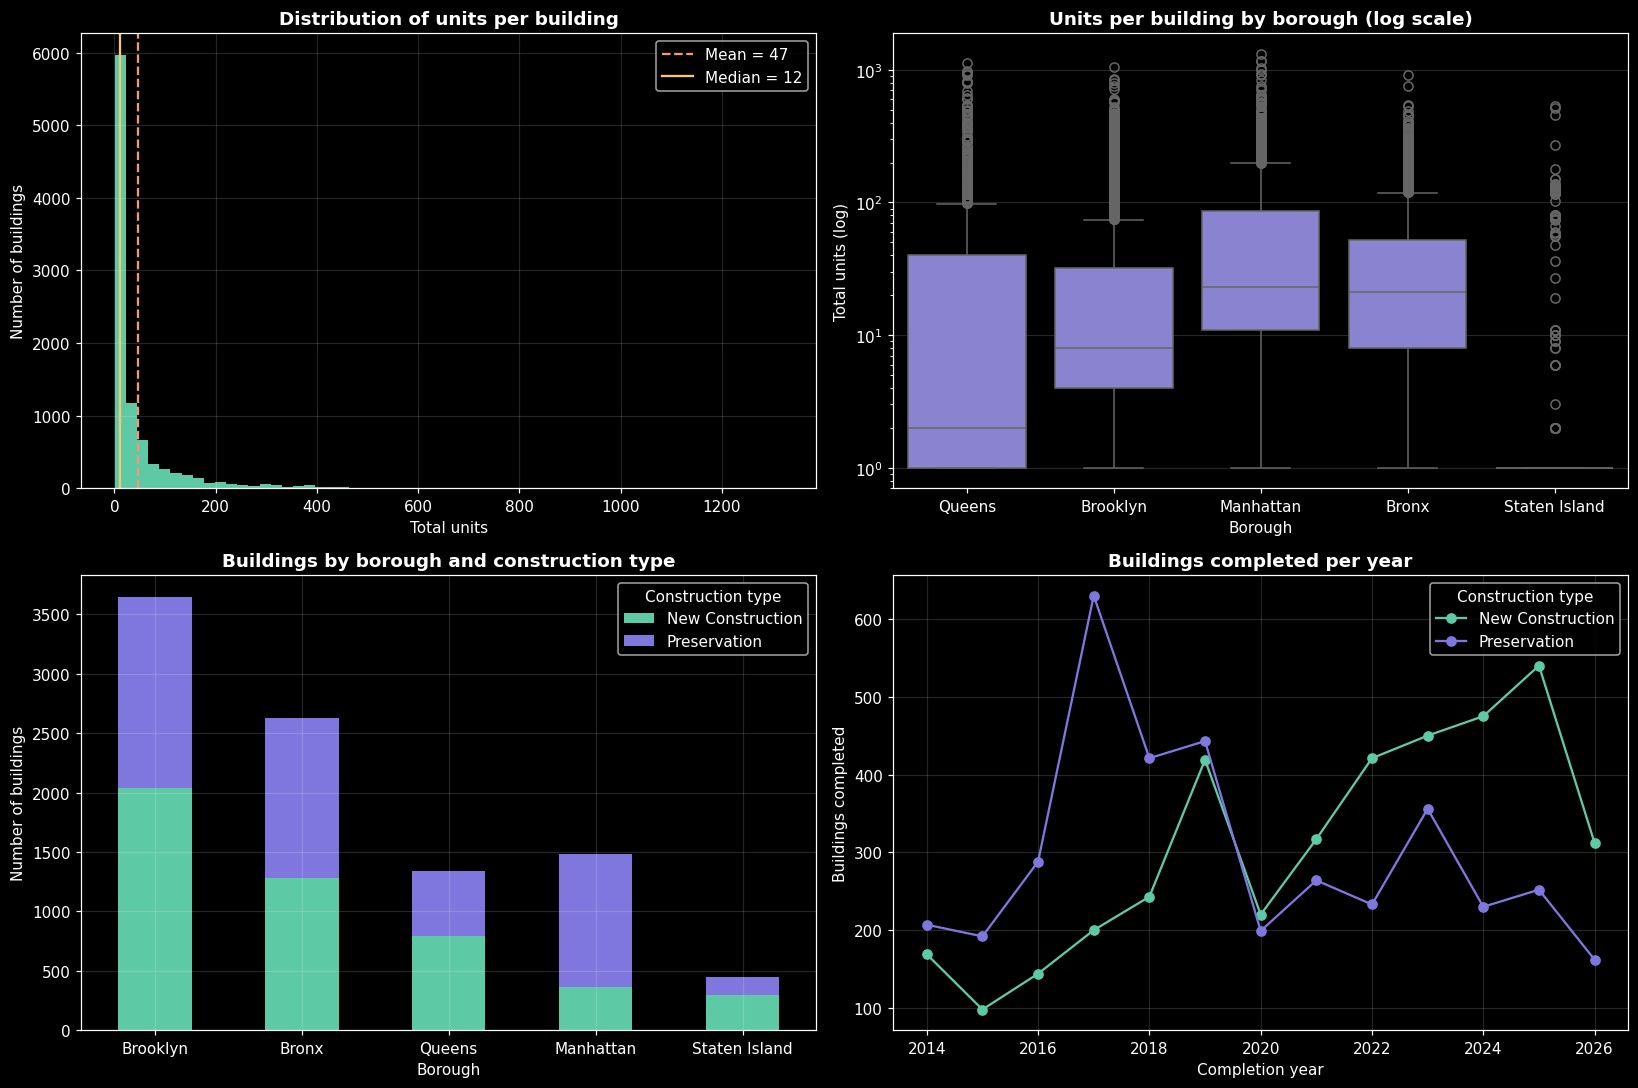

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
units = df_housing['total_units'].dropna()

# 1. Distribution – histogram with mean vs median
ax = axes[0, 0]
ax.hist(units, bins=60, color='#5DCAA5', edgecolor='none')
ax.axvline(units.mean(), color='#F0997B', ls='--', label=f'Mean = {units.mean():.0f}')
ax.axvline(units.median(), color='#FAC775', ls='-', label=f'Median = {units.median():.0f}')
ax.set(title='Distribution of units per building', xlabel='Total units', ylabel='Number of buildings')
ax.legend()

# 2. Outliers – box plot by borough (log scale so small buildings remain visible)
ax = axes[0, 1]
sns.boxplot(data=df_housing, x='borough', y='total_units', ax=ax, color='#7F77DD')
ax.set_yscale('log')
ax.set(title='Units per building by borough (log scale)', xlabel='Borough', ylabel='Total units (log)')

# 3. Comparison + composition – stacked bar
ax = axes[1, 0]
pd.crosstab(df_housing['borough'], df_housing['reporting_construction_type']) \
  .sort_values('New Construction', ascending=False) \
  .plot(kind='bar', stacked=True, ax=ax, color=['#5DCAA5', '#7F77DD'], rot=0)
ax.set(title='Buildings by borough and construction type', xlabel='Borough', ylabel='Number of buildings')
ax.legend(title='Construction type')

# 4. Trend – completed buildings per year
ax = axes[1, 1]
completion_year = pd.to_datetime(df_housing['building_completion_date'], errors='coerce').dt.year
pd.crosstab(completion_year, df_housing['reporting_construction_type']) \
  .plot(ax=ax, marker='o', color=['#5DCAA5', '#7F77DD'])
ax.set(title='Buildings completed per year', xlabel='Completion year', ylabel='Buildings completed')
ax.legend(title='Construction type')

plt.tight_layout()
plt.show()

### 5.4 Housing – EDA Findings

**Hypothesis tests**
| # | Result | Evidence | Consequence for cleaning |
|---|---|---|---|
| H1 | ✅ **Confirmed** | 1,949 of the 1,958 buildings without coordinates are named `CONFIDENTIAL` | They cannot be mapped; keep them for borough / community-board analysis and exclude them from the ZIP and distance analysis. The 9 non-confidential buildings without a location are investigated separately. |
| H2 | ✅ **Confirmed** | Income bands (blanks as 0) add up to `all_counted_units` in **99.7%** of rows | Blank income-band cells are **structural zeros**: fill with **0**, not the mean or median. The remaining 0.3% is checked in cleaning. |
| H3 | ✅ **Confirmed** | Median start year is **2019** for completed buildings vs. **2024** for those without a completion date; the share missing rises from 0% (2014 starts) to 60% (2026 starts) | Missing completion dates mean **"not finished yet"**, not data errors. These buildings are excluded only from the before/after-completion analysis. |

**`total_units` vs. `all_counted_units`:** `total_units` counts every apartment, while `all_counted_units` counts only the affordable units counted toward the city's housing plan (the sum of the income bands). Income questions use `all_counted_units`; density questions use `total_units`.

**Distribution (Lecture 3)**
- `total_units` is strongly **positively skewed** (skewness 4.59): **mean 47 vs. median 12**, mode 1.
- A few very large developments (max 1,320 units) pull the mean up, so the **median** is the representative "typical building" and is used in all summaries.

**Outliers**
- The box plot shows many points above the upper whisker (Q3 + 1.5 × IQR) in every borough.
- These are **real large developments**, not errors: 1,320 units is plausible for a NYC tower. Following the domain rule *"is this value possible?"*, they are **kept**. Log scales and medians handle the skew instead of deleting valid data.

**Borough patterns**
- **Brooklyn (3,649) and the Bronx (2,630)** have the most affordable buildings; **Staten Island (445)** has the fewest.
- **Manhattan** has the largest buildings (highest median) and is mostly **Preservation**; **Queens and Staten Island** are dominated by 1–2-unit homes (Staten Island's box sits at 1 unit).
- Citywide, the split between New Construction (4,766) and Preservation (4,785) is almost exactly even.

**Trends over time**
- **New Construction rises steadily** from about 100 buildings (2015) to about 540 (2025), overtaking Preservation from 2020 onwards.
- Preservation peaks sharply in **2017** (about 630 buildings).
- Both types dip in **2020** (COVID-19 construction slowdown).
- **2026 is incomplete** (the year is still running and many projects are unfinished), so its drop is not a real decline.

### 5.5 Crashes – Testing the Known-Issues Hypotheses & Data Quality

| # | Check | Why it matters |
|---|---|---|
| C1 | How many crashes **missing a ZIP still have coordinates**? | If most do, ZIPs can be recovered from latitude/longitude instead of dropping a third of the data |
| C2 | **Noisy coordinates**: `(0, 0)` or points outside NYC | Like the lecture's "age = –20", these are impossible values that would distort maps and spatial joins |
| C3 | Duplicate `collision_id` | No exact duplicate rows were found, but the same crash could appear twice with small differences |
| C4 | **Negative** injury / death counts | Counts are ratio-scale and cannot be negative |
| C5 | Format of `zip_code` | ZIPs are nominal labels; check whether they were read as numbers (e.g. `11201.0`) |

In [ ]:
lat, lon = df_transport['latitude'], df_transport['longitude']
has_coords = lat.notna() & lon.notna()
no_zip = df_transport['zip_code'].isna()

# C1 – recoverable ZIPs
print(f'C1 – Crashes missing ZIP: {no_zip.sum():,}')
print(f'     ...of which have coordinates (recoverable): {(no_zip & has_coords).sum():,} '
      f'({(no_zip & has_coords).sum() / no_zip.sum():.1%})')
print(f'     ...with neither ZIP nor coordinates (unusable for location): {(no_zip & ~has_coords).sum():,}\n')

# C2 – noisy coordinates (NYC bounding box ≈ lat 40.49–40.92, lon -74.27 to -73.68)
zero_coords = has_coords & ((lat == 0) | (lon == 0))
inside_nyc = lat.between(40.49, 40.92) & lon.between(-74.27, -73.68)
outside_nyc = has_coords & ~zero_coords & ~inside_nyc
print(f'C2 – Coordinates at (0, 0): {zero_coords.sum():,}')
print(f'     Coordinates outside NYC: {outside_nyc.sum():,}\n')

# C3 – duplicate collision IDs
print(f'C3 – Duplicate collision_id values: {df_transport["collision_id"].duplicated().sum():,}\n')

# C4 – negative counts
COUNT_COLS = [c for c in df_transport.columns if c.startswith('number_of_')]
negatives = (df_transport[COUNT_COLS] < 0).sum()
print('C4 – Negative values per count column:')
print(negatives[negatives > 0].to_string() if negatives.any() else '     none', '\n')

# C5 – ZIP format
print(f'C5 – zip_code dtype: {df_transport["zip_code"].dtype}')
print('     Sample values:', df_transport['zip_code'].dropna().unique()[:8])

C1 – Crashes missing ZIP: 508,155
     ...of which have coordinates (recoverable): 420,334 (82.7%)
     ...with neither ZIP nor coordinates (unusable for location): 87,821

C2 – Coordinates at (0, 0): 6,770
     Coordinates outside NYC: 150

C3 – Duplicate collision_id values: 0

C4 – Negative values per count column:
     none 

C5 – zip_code dtype: float64
     Sample values: [10019. 11217. 11229. 10022. 10461. 11372. 11208. 11422.]


### 5.6 Crashes – Central Tendency & Dispersion (Lecture 3)

Each row is one crash, so the key ratio-scale variables are **injuries and deaths per crash**. Because our integration level is **ZIP × year**, we also look ahead at the distribution of **crashes per ZIP per year**: if it is heavily skewed, the median must be used when comparing areas.

In [ ]:
crash_dates = pd.to_datetime(df_transport['crash_date'], errors='coerce')
crash_year = crash_dates.dt.year

describe_numeric(df_transport['number_of_persons_injured'], 'persons injured per crash')

print(f'Crashes with at least one injury: {(df_transport["number_of_persons_injured"] > 0).mean():.1%}')
print(f'Crashes with at least one death : {(df_transport["number_of_persons_killed"] > 0).mean():.2%}')
print(f'Total persons killed 2016-2025  : {df_transport["number_of_persons_killed"].sum():,.0f}\n')

print('Crashes per year:')
print(crash_year.value_counts().sort_index().to_string(), '\n')

# Preview of the integration level: crashes per ZIP per year
crashes_per_zip_year = df_transport.dropna(subset=['zip_code']) \
                                   .groupby(['zip_code', crash_year]).size()
describe_numeric(crashes_per_zip_year, 'crashes per ZIP per year')

--- persons injured per crash (n = 1,504,726) ---
Mean 0.4 | Median 0.0 | Mode 0 | Std 0.7
Five-number summary: min 0 | Q1 0 | median 0 | Q3 1 | max 40
IQR 1 | Skewness 3.72  (positively skewed)

Crashes with at least one injury: 27.1%
Crashes with at least one death : 0.17%
Total persons killed 2016-2025  : 2,610

Crashes per year:
crash_date
2016    229835
2017    231007
2018    231564
2019    211487
2020    112923
2021    110558
2022    103887
2023     96608
2024     91316
2025     85559 

--- crashes per ZIP per year (n = 2,121) ---
Mean 469.9 | Median 370.0 | Mode 1 | Std 445.7
Five-number summary: min 1 | Q1 131 | median 370 | Q3 666 | max 2744
IQR 535 | Skewness 1.34  (positively skewed)



### 5.7 Crashes – Visual Exploration (Lectures 3–4)

| Chart | Job | Why this type |
|---|---|---|
| Line: crashes per year | **Trend** | Shows the long-term pattern and the 2020 COVID drop |
| Line: injuries by road-user type | **Trend, comparing groups** | 3 lines (pedestrians, cyclists, motorists), within the 4–5 line limit |
| Bar: crashes by hour of day | **Distribution of a time attribute** | Shows when crashes happen; hour is a discrete category here |
| Box plot: crashes per ZIP-year by borough | **Distribution + outliers by group** | Previews the integration level and shows which ZIPs are extreme |

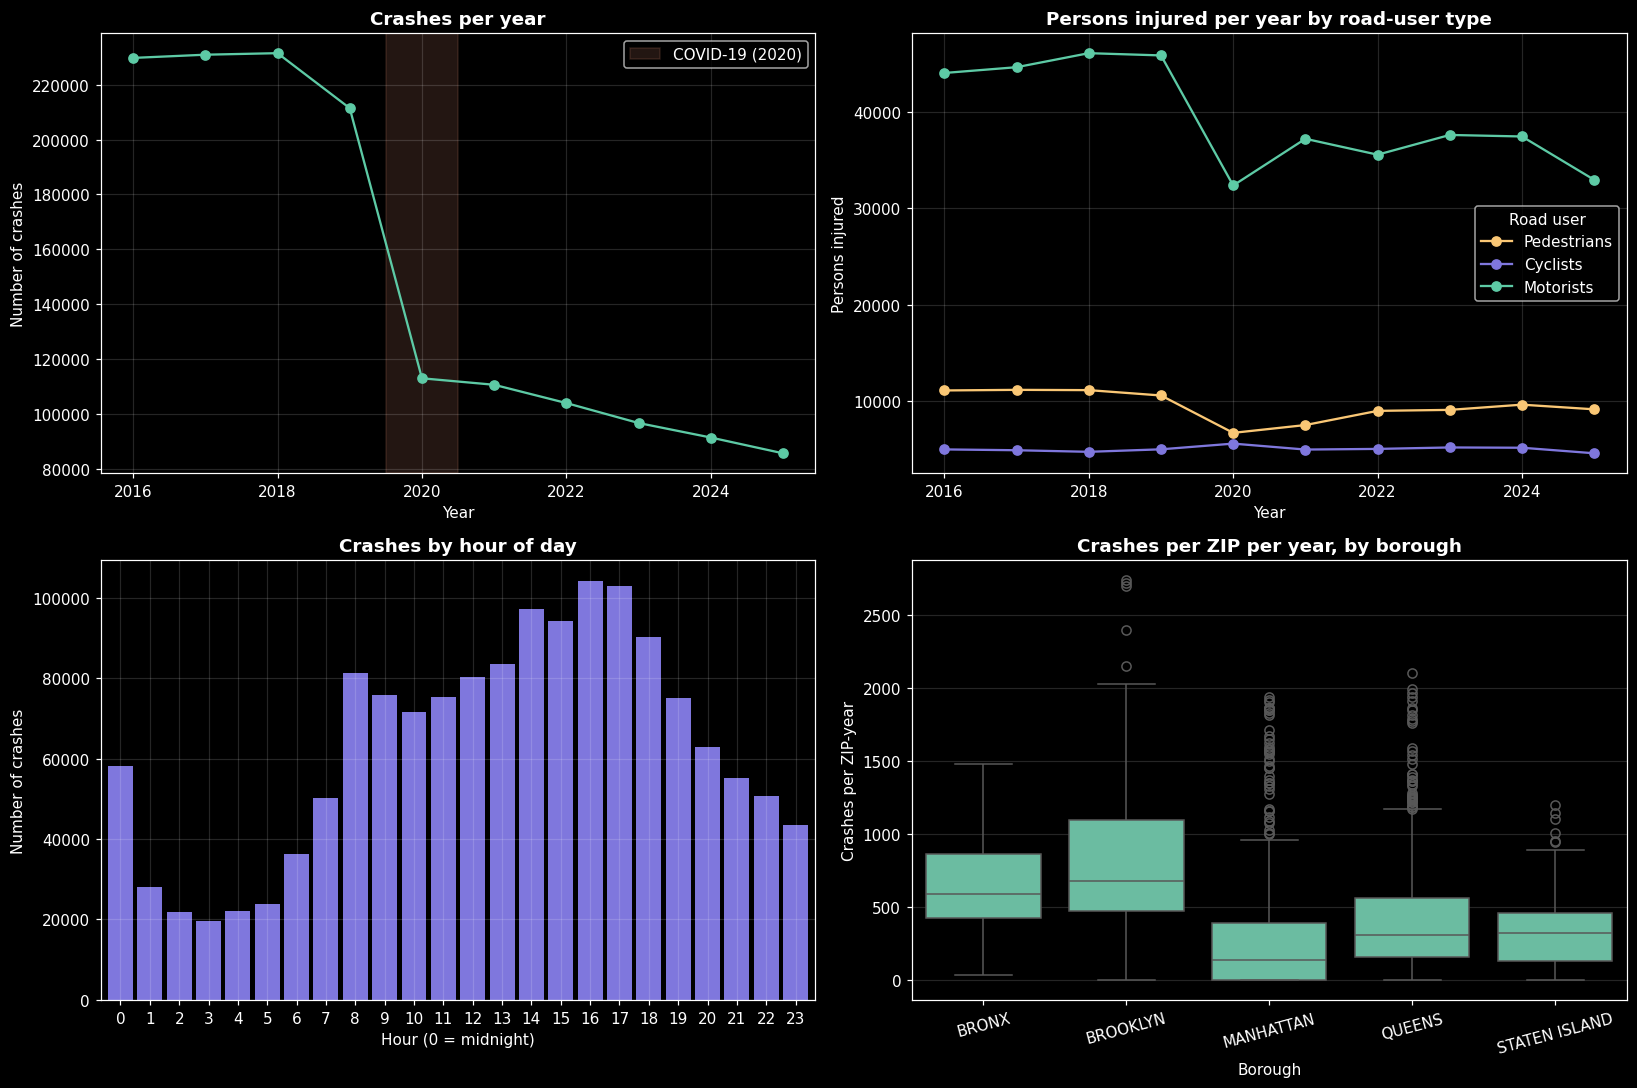

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Trend – crashes per year
ax = axes[0, 0]
yearly = crash_year.value_counts().sort_index()
ax.plot(yearly.index, yearly.values, marker='o', color='#5DCAA5')
ax.axvspan(2019.5, 2020.5, color='#F0997B', alpha=0.15, label='COVID-19 (2020)')
ax.set(title='Crashes per year', xlabel='Year', ylabel='Number of crashes')
ax.legend()

# 2. Trend by group – injuries by road-user type
ax = axes[0, 1]
injuries = df_transport.groupby(crash_year)[['number_of_pedestrians_injured',
                                             'number_of_cyclist_injured',
                                             'number_of_motorist_injured']].sum()
injuries.columns = ['Pedestrians', 'Cyclists', 'Motorists']
injuries.plot(ax=ax, marker='o', color=['#FAC775', '#7F77DD', '#5DCAA5'])
ax.set(title='Persons injured per year by road-user type', xlabel='Year', ylabel='Persons injured')
ax.legend(title='Road user')

# 3. Distribution – crashes by hour of day
ax = axes[1, 0]
crash_hour = df_transport['crash_time'].astype(str).str.split(':').str[0].astype(int)
crash_hour.value_counts().sort_index().plot(kind='bar', ax=ax, color='#7F77DD', rot=0, width=0.85)
ax.set(title='Crashes by hour of day', xlabel='Hour (0 = midnight)', ylabel='Number of crashes')

# 4. Distribution + outliers – crashes per ZIP-year by borough
ax = axes[1, 1]
zip_year_borough = df_transport.dropna(subset=['zip_code', 'borough']) \
                               .groupby(['borough', 'zip_code', crash_year]).size() \
                               .rename('crashes').reset_index()
sns.boxplot(data=zip_year_borough, x='borough', y='crashes', ax=ax, color='#5DCAA5')
ax.set(title='Crashes per ZIP per year, by borough', xlabel='Borough', ylabel='Crashes per ZIP-year')
ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

### 5.8 Crashes – EDA Findings

**Data quality checks**
| # | Result | Consequence for cleaning |
|---|---|---|
| C1 | **508,155** crashes (33.8%) have no ZIP, but **420,334 of them (82.7%) have coordinates** | Recover ZIPs from latitude/longitude using the nearest crashes with a known ZIP (k-NN, see Section 6.5; multivariate imputation from another attribute) instead of dropping a third of the data. Only **87,821** crashes (5.8%) have neither, and they are excluded from location-based analysis. |
| C2 | **6,770** crashes at `(0, 0)` and **150** outside NYC | Impossible values (noisy data, like the lecture's "age = –20"). Their coordinates are set to missing; any ZIP they have is kept. |
| C3 | 0 duplicate `collision_id` values | No de-duplication needed: each row is a unique crash. |
| C4 | No negative counts | The count columns pass the "possible value" check. |
| C5 | `zip_code` was read as **float** (`10019.0`) | Inconsistent format: a ZIP is a nominal label, so it is converted to a 5-character string to match the housing `postcode`. |
| — | `borough` is **UPPERCASE** here (`BROOKLYN`) but Title Case in housing (`Brooklyn`) | Standardise before integration. |

**Injuries per crash (Lecture 3)**
- **Median 0, mean 0.4, mode 0**, skewness 3.72: most crashes are property damage only. **72.9% injure nobody**, 27.1% injure at least one person, and 0.17% are fatal (2,610 deaths in 2016–2025).
- The maximum of **40 injured** in a single crash is extreme but plausible (for example, a bus crash), so it is **kept**.

**Trend: crashes fell, but severity rose**
- Crashes were stable at about **230k per year (2016–2018)**, fell **47% in 2020** (COVID-19), and **never recovered**, declining further to **85.6k in 2025** (–63% vs. 2016).
- **Injuries fell much less.** In 2016 there were roughly 0.26 injured persons per crash; by 2025 it is about 0.54, i.e. **roughly double**.
- **Interpretation:** crash *counts* alone are a misleading measure of street danger, because they mix minor fender-benders (which may be reported less often than before) with serious crashes. Our safety measures therefore focus on **injuries and deaths**, not just the number of crashes. *(Possible change in how minor crashes are reported is noted as a limitation; we cannot prove why counts dropped.)*
- **Cyclist injuries stayed flat at about 5k per year and even rose slightly in 2020**, while pedestrian and motorist injuries dropped, consistent with the 2020 cycling boom.

**Time of day**
- Crashes are lowest at **3 a.m.**, with a morning peak at **8 a.m.** and the main peak at **4–5 p.m.** (evening rush hour).
- **Suspicious spike at midnight (hour 0):** about 58k crashes, twice as many as at 1 a.m. This is likely **disguised missing data**: `00:00` used as a placeholder when the real time is unknown (the same pattern as the lecture's "birthdate = January 1st"). It is checked in cleaning and noted in any time-of-day analysis.

**Crashes per ZIP per year (preview of the integration level)**
- **2,121** ZIP-years; **median 370 vs. mean 470** (skewness 1.34), so **medians** are used when comparing areas.
- **Brooklyn** has the highest median per ZIP (≈680) and the **Bronx** comes next (≈590); **Manhattan** has the lowest median (≈140) but many high outliers. Manhattan has many tiny ZIP codes (some cover a single building) alongside very busy Midtown ZIPs.
- **Min = 1 and mode = 1:** some ZIP-years have a single crash, likely special-purpose ZIPs (single buildings, P.O. boxes). These are flagged in cleaning because they would distort per-ZIP comparisons.
- The high outliers (up to 2,744) are **real busy areas**, not errors, so they are **kept**.



---



---



## 6. Pre-Integration Cleaning

Each dataset is cleaned **separately, before the join**, so that join keys and formats are correct and errors do not spread into the integrated table. Every action below is traced back to an EDA finding (Sections 5.4 and 5.8) and to a technique from the *Data Preprocessing* lecture.

We work on **copies**; the raw DataFrames stay untouched for comparison.

### 6.1 Housing – Cleaning Plan
| Problem (EDA finding) | Action | Technique | Justification |
|---|---|---|---|
| Dates stored as text | Convert to `datetime` | Standardise formats | Needed for year extraction and before/after comparisons |
| `postcode` read as float (`11201.0`) | 5-character string, renamed to `zip_code` | Inconsistent formatting + schema integration | A ZIP is a nominal label; the name and format must match the crash data |
| `borough` / category spelling | Strip spaces, Title Case | Inconsistent formatting | One spelling per category (like "US" vs. "U.S.") |
| Blank income-band and bedroom cells | Fill with **0** | Global constant | Proven structural zeros (H2: bands add up to `all_counted_units` in 99.7% of rows). The mean or median would invent units that do not exist. |
| 29 blank `all_counted_units` | Fill with the income-band total | Imputation from other attributes | `all_counted_units` is defined as the sum of the bands |
| Confidential / unlocated buildings | **Keep and flag** (`has_location`) | Avoid ignoring the tuple | Dropping 20% would bias borough totals; they are only excluded from map / ZIP analysis |
| Unfinished projects | **Keep and flag** (`is_completed`) | Avoid ignoring the tuple | A missing date means "not finished", not an error (H3) |
| Very large buildings (IQR outliers) | **Keep and flag** | Domain rule | Real developments, not errors |
| Logically impossible rows | Check and remove | Noisy data | e.g. more affordable units than total units, completion before start |

In [ ]:
housing = df_housing.copy()

# --- Dates: text -> datetime (unparseable values become NaT) ---
DATE_COLS = ['project_start_date', 'project_completion_date', 'building_completion_date']
for col in DATE_COLS:
    housing[col] = pd.to_datetime(housing[col], errors='coerce')

# --- ZIP: float -> 5-char string, and same column name as the crash data ---
housing = housing.rename(columns={'postcode': 'zip_code'})
housing['zip_code'] = housing['zip_code'].astype('Int64').astype('string').str.zfill(5)

# --- Text categories: remove stray spaces, one consistent case ---
TEXT_COLS = ['borough', 'reporting_construction_type',
             'extended_affordability_status', 'prevailing_wage_status']
for col in TEXT_COLS:
    housing[col] = housing[col].astype('string').str.strip().str.title()

# --- Area codes are labels, not numbers ---
for col in ['census_tract', 'community_board', 'council_district']:
    housing[col] = housing[col].astype('string')

print(housing[['zip_code', 'borough', 'building_completion_date']].dtypes, '\n')
for col in TEXT_COLS:
    print(f'{col}: {housing[col].value_counts(dropna=False).to_dict()}')

zip_code                    string[python]
borough                     string[python]
building_completion_date    datetime64[ns]
dtype: object 

borough: {'Brooklyn': 3649, 'Bronx': 2630, 'Manhattan': 1485, 'Queens': 1342, 'Staten Island': 445}
reporting_construction_type: {'Preservation': 4785, 'New Construction': 4766}
extended_affordability_status: {'No': 8125, 'Yes': 1426}
prevailing_wage_status: {'Non Prevailing Wage': 9392, 'Prevailing Wage': 159}


In [ ]:
from IPython.display import display

def section(title):
    """Print a clear header so each part of the output is easy to find."""
    print(f'\n{"─" * 60}\n{title}\n{"─" * 60}')

INCOME_COLS = ['extremely_low_income_units', 'very_low_income_units', 'low_income_units',
               'moderate_income_units', 'middle_income_units', 'other_income_units']
BEDROOM_COLS = ['studio_units', '_1_br_units', '_2_br_units', '_3_br_units',
                '_4_br_units', '_5_br_units', '_6_br_units', 'unknown_br_units']
TENURE_COLS = ['counted_rental_units', 'counted_homeownership_units']

# ---------- 1. Structural zeros: blank = "no units of this kind" (proven by H2) ----------
section('1. Structural zeros')
zero_fill_cols = INCOME_COLS + BEDROOM_COLS + TENURE_COLS
blanks_before = int(housing[zero_fill_cols].isna().sum().sum())
housing[zero_fill_cols] = housing[zero_fill_cols].fillna(0).astype(int)
print(f'Blank cells filled with 0: {blanks_before:,} across {len(zero_fill_cols)} columns')

# ---------- 2. Rebuild missing all_counted_units from the income bands ----------
section('2. all_counted_units')
band_sum = housing[INCOME_COLS].sum(axis=1)
print(f'Blank values filled from income bands: {housing["all_counted_units"].isna().sum()}')
housing['all_counted_units'] = housing['all_counted_units'].fillna(band_sum).astype(int)

# Check that every row now matches (only the mismatching rows are shown)
mismatch_mask = band_sum != housing['all_counted_units']
mismatch = housing.loc[mismatch_mask, ['project_name', 'all_counted_units', 'total_units']] \
                  .assign(band_sum=band_sum[mismatch_mask])
print(f'Rows where income bands ≠ all_counted_units: {len(mismatch)}')
if len(mismatch) > 0:
    display(mismatch.head(10))

# ---------- 3. Flags instead of deletion ----------
section('3. Flags')
housing['is_confidential'] = housing['project_name'].str.upper().str.contains('CONFIDENTIAL', na=False)
housing['has_location'] = housing['latitude'].notna() & housing['longitude'].notna()
housing['is_completed'] = housing['building_completion_date'].notna()

flag_summary = pd.DataFrame({
    'True':  [housing['has_location'].sum(), housing['is_completed'].sum(), housing['is_confidential'].sum()],
    'False': [(~housing['has_location']).sum(), (~housing['is_completed']).sum(), (~housing['is_confidential']).sum()]
}, index=['has_location', 'is_completed', 'is_confidential'])
display(flag_summary)

# ---------- 4. Non-confidential buildings without location ----------
section('4. Non-confidential buildings without location')
display(housing.loc[~housing['has_location'] & ~housing['is_confidential'],
                    ['project_name', 'borough', 'house_number', 'street_name', 'zip_code']])


────────────────────────────────────────────────────────────
1. Structural zeros
────────────────────────────────────────────────────────────
Blank cells filled with 0: 106,280 across 16 columns

────────────────────────────────────────────────────────────
2. all_counted_units
────────────────────────────────────────────────────────────
Blank values filled from income bands: 29
Rows where income bands ≠ all_counted_units: 0

────────────────────────────────────────────────────────────
3. Flags
────────────────────────────────────────────────────────────


,True,False
has_location,7593,1958
is_completed,7885,1666
is_confidential,1949,7602



────────────────────────────────────────────────────────────
4. Non-confidential buildings without location
────────────────────────────────────────────────────────────


,project_name,borough,house_number,street_name,zip_code
467,122-21 14TH AVENUE,Queens,1422-21,14 AVENUE,<NA>
560,ARVERNE EAST - BUILDING D - RENTAL,Queens,3541,BEACH 36 STREET,<NA>
561,ARVERNE EAST OPEN DOOR,Queens,3541,BEACH 36 STREET,<NA>
563,75-42 GRAND CENTRAL PARKWAY,Queens,75-42,GRAND CENTRAL PARKWAY NORTH,<NA>
751,LE GRANDE VILLE,Bronx,1701,WEST 176 STREET,<NA>
769,OCEAN CREST,Queens,726,BEACH CHANNEL DRIVE,<NA>
1980,470 KENT AVENUE,Brooklyn,11,WHARF WAY,<NA>
3313,101-19 ROCKAWAY BEACH BOULEVARD,Queens,101-19,ROCKAWAY BEACH BOULEVAR,<NA>
6806,SOUTHEASTERN QUEENS VACANT HOMES-CLUSTER II,Queens,133-16,VAN WYCK EXPRESSWAY SR WEST,<NA>


In [ ]:
# --- Impossible values (domain rules) ---
too_many_counted = housing['all_counted_units'] > housing['total_units']
finished_before_start = housing['building_completion_date'] < housing['project_start_date']
outside_nyc = housing['has_location'] & ~(housing['latitude'].between(40.49, 40.92) &
                                          housing['longitude'].between(-74.27, -73.68))
print(f'More affordable units than total units : {too_many_counted.sum()}')
print(f'Completed before the project started   : {finished_before_start.sum()}')
print(f'Coordinates outside NYC                : {outside_nyc.sum()}')

impossible = too_many_counted | finished_before_start | outside_nyc
housing = housing[~impossible].copy()
print(f'-> Removed {impossible.sum()} impossible rows\n')

# --- Outliers: IQR rule to FLAG, domain rule to KEEP ---
q1, q3 = housing['total_units'].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
housing['is_large_building'] = housing['total_units'] > upper_fence
print(f'IQR upper fence: {upper_fence:.0f} units -> {housing["is_large_building"].sum():,} '
      f'large buildings flagged (kept: real developments)\n')

# --- Duplicates ---
print(f'Exact duplicate rows: {housing.duplicated().sum()}')
print(f'Duplicate (project_id, building_id) pairs: {housing.duplicated(["project_id", "building_id"]).sum()}')
print(f'Buildings appearing in more than one project: '
      f'{housing["building_id"].dropna().duplicated().sum()}  (legitimate: e.g. preserved again later)')
housing = housing.drop_duplicates(['project_id', 'building_id'])

More affordable units than total units : 0
Completed before the project started   : 20
Coordinates outside NYC                : 0
-> Removed 20 impossible rows

IQR upper fence: 108 units -> 1,171 large buildings flagged (kept: real developments)

Exact duplicate rows: 0
Duplicate (project_id, building_id) pairs: 0
Buildings appearing in more than one project: 124  (legitimate: e.g. preserved again later)


In [ ]:
# --- Derived attributes for the research questions ---
housing['start_year'] = housing['project_start_date'].dt.year
housing['completion_year'] = housing['building_completion_date'].dt.year.astype('Int64')
housing['affordable_share'] = (housing['all_counted_units'] / housing['total_units']).round(3)
housing['lowest_income_units'] = housing['extremely_low_income_units'] + housing['very_low_income_units']

# --- Redundant columns: internal coordinates duplicate latitude/longitude ---
housing = housing.drop(columns=['latitude_internal', 'longitude_internal'])

os.makedirs(DATA_DIR + 'clean/', exist_ok=True)
housing.to_parquet(DATA_DIR + 'clean/housing_clean.parquet', index=False)

print(f'Raw: {df_housing.shape} -> Clean: {housing.shape}\n')
print('Remaining missing values (columns with any):')
remaining = housing.isna().mean()
print(remaining[remaining > 0].sort_values(ascending=False).round(3).to_string())

Raw: (9551, 41) -> Clean: (9531, 47)

Remaining missing values (columns with any):
bbl                             0.212
bin                             0.212
zip_code                        0.205
latitude                        0.205
longitude                       0.205
census_tract                    0.205
neighborhood_tabulation_area    0.205
building_id                     0.204
project_completion_date         0.191
building_completion_date        0.175
completion_year                 0.175


### 6.2 Housing – Derived Attributes
| New column | Formula | Why |
|---|---|---|
| `start_year`, `completion_year` | Year of the start / building completion date | The time key for integration (ZIP × year) |
| `affordable_share` | `all_counted_units / total_units` | Separates 100%-affordable buildings from mixed-income ones |
| `lowest_income_units` | Extremely low + very low income units | Directly answers "where are the *lowest-income* units built?" |
| `has_location`, `is_completed`, `is_confidential`, `is_large_building` | Boolean flags | Rows are **kept and filtered per analysis** instead of deleted, so no information is lost |

**Remaining missing values are expected:** location fields for confidential buildings and completion dates for unfinished projects. Both are handled with the flags above.

### 6.3 Housing – Cleaning Results

**Raw (9,551 × 41) → Clean (9,531 × 47)**: 20 rows removed, 8 columns added (flags and derived features), 2 redundant columns dropped.

| Action | Result |
|---|---|
| Formats standardised | Dates → `datetime`; `zip_code` → 5-character string; categories consistent (5 boroughs, 2 construction types, Yes/No statuses: no spelling variants found) |
| Structural zeros | **106,280** blank income-band, bedroom and tenure cells filled with 0 |
| `all_counted_units` | **29** blanks rebuilt from the income bands. After this, the bands match `all_counted_units` in **100%** of rows: the 0.3% mismatch found in EDA was exactly these 29 rows. |
| Impossible values | **20** buildings with a completion date *before* their project start were removed (0.2%): a logically impossible order, most likely data-entry errors. No buildings had more affordable units than total units, and none had coordinates outside NYC. |
| Outliers | IQR upper fence = **108 units**; **1,171** large buildings flagged and **kept** (real developments, domain rule) |
| Duplicates | No exact duplicates, no repeated `(project_id, building_id)` pairs. **124** buildings appear in more than one project; this is legitimate (e.g. a building preserved again in a later program) and is kept. |

**The 9 non-confidential buildings without location**
These have real addresses but no coordinates, and several show **inaccurate data** (Preprocessing lecture, *data quality: accuracy*):
- house number `1422-21` for the project *122-21 14th Avenue* (a typo),
- `ROCKAWAY BEACH BOULEVAR` (a truncated street name),
- a highway service road (`VAN WYCK EXPRESSWAY SR WEST`) given as a street.

At 9 rows (0.1%), geocoding them by hand is not worth it, so they are **kept and flagged** (`has_location = False`) and excluded only from map / ZIP analysis.

**Remaining missing values are all explained**
| Column(s) | % missing | Reason |
|---|---|---|
| `zip_code`, `latitude`, `longitude`, `census_tract`, `neighborhood_tabulation_area`, `building_id`, `bbl`, `bin` | 20–21% | Confidential addresses (+ the 9 above) |
| `project_completion_date` | 19.1% | Project still in progress |
| `building_completion_date`, `completion_year` | 17.5% | Building still in progress |

No missing value is left unexplained, and none was filled with an invented value.



---



### 6.4 Crashes – Cleaning Plan
| Problem (EDA finding) | Action | Technique | Justification |
|---|---|---|---|
| Vehicle 3–5 columns 92–99.5% empty; `location` repeats lat/lon; cross/off-street names not needed | Drop 9 columns | Data reduction (dimensionality) | Not used by any research question; saves memory |
| 1.5 GB in memory | Smaller number types; categories for repeated text | Data reduction | Faster processing in Colab and in the website |
| `zip_code` stored as float | 5-character string | Inconsistent formatting | A ZIP is a nominal label; must match the housing `zip_code` |
| `borough` in UPPERCASE | Title Case | Inconsistent formatting | Must match the housing spelling (`Brooklyn`) |
| 18 blank `persons_injured` / `persons_killed` | Rebuild from pedestrians + cyclists + motorists | Imputation from other attributes | "Persons" is by definition the sum of the three road-user groups |
| 6,770 crashes at `(0, 0)` + 150 outside NYC | Set coordinates to missing | Noisy data | Impossible locations would corrupt the ZIP recovery and maps |
| 420k crashes without ZIP but **with** coordinates | Recover the ZIP from the **5 nearest crashes with a known ZIP** (k-nearest neighbours), validated on held-out data; only within 300 m | Multivariate imputation ("most probable value") | Avoids dropping 28% of the data; accuracy is measured, not assumed |
| Missing `borough` | Derive from the (recovered) ZIP | Imputation from other attributes | Each ZIP belongs to one borough |
| Midnight spike (`00:00`) | Test, then flag as `time_unknown` | Disguised missing data | Like "birthdate = Jan 1st": a default value, not a real time |
| Crashes with no ZIP and no coordinates | Remove (after checking for a pattern) | Ignore the tuple | They cannot be linked to any area, so they cannot be integrated |

In [ ]:
crashes = df_transport.copy()
mem_before = crashes.memory_usage(deep=True).sum() / 1e6

# --- Data reduction: columns no research question uses ---
DROP_COLS = ['vehicle_type_code_3', 'vehicle_type_code_4', 'vehicle_type_code_5',
             'contributing_factor_vehicle_3', 'contributing_factor_vehicle_4',
             'contributing_factor_vehicle_5', 'location', 'off_street_name', 'cross_street_name']
crashes = crashes.drop(columns=DROP_COLS)

# --- Formats ---
crashes['crash_date'] = pd.to_datetime(crashes['crash_date'], errors='coerce')
crashes['crash_year'] = crashes['crash_date'].dt.year.astype('int16')
crashes['zip_code'] = crashes['zip_code'].astype('Int64').astype('string').str.zfill(5)
crashes['borough'] = crashes['borough'].astype('string').str.strip().str.title()

# --- Rebuild the 18 blank totals from their components (persons = ped + cyc + motorist) ---
for outcome in ['injured', 'killed']:
    parts = crashes[[f'number_of_pedestrians_{outcome}', f'number_of_cyclist_{outcome}',
                     f'number_of_motorist_{outcome}']].sum(axis=1)
    total_col = f'number_of_persons_{outcome}'
    print(f'Blank {total_col} rebuilt from components: {crashes[total_col].isna().sum()}')
    crashes[total_col] = crashes[total_col].fillna(parts)

COUNT_COLS = [c for c in crashes.columns if c.startswith('number_of_')]
crashes[COUNT_COLS] = crashes[COUNT_COLS].fillna(0).astype('int16')

# --- Repeated text -> 'category' dtype (much less memory) ---
for col in ['contributing_factor_vehicle_1', 'contributing_factor_vehicle_2',
            'vehicle_type_code1', 'vehicle_type_code2', 'on_street_name']:
    crashes[col] = crashes[col].astype('string').str.strip().str.title().astype('category')
crashes['borough'] = crashes['borough'].astype('category')

mem_after = crashes.memory_usage(deep=True).sum() / 1e6
print(f'\nColumns: {df_transport.shape[1]} -> {crashes.shape[1]}')
print(f'Memory : {mem_before:,.0f} MB -> {mem_after:,.0f} MB')
print(f'Boroughs now: {crashes["borough"].cat.categories.tolist()}')

Blank number_of_persons_injured rebuilt from components: 18
Blank number_of_persons_killed rebuilt from components: 31

Columns: 29 -> 21
Memory : 1,514 MB -> 364 MB
Boroughs now: ['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island']


In [ ]:
lat, lon = crashes['latitude'], crashes['longitude']
is_zero = (lat == 0) | (lon == 0)
in_nyc = lat.between(40.49, 40.92) & lon.between(-74.27, -73.68)
bad_coords = lat.notna() & lon.notna() & (is_zero | ~in_nyc)

crashes.loc[bad_coords, ['latitude', 'longitude']] = np.nan
print(f'Noisy coordinates set to missing: {bad_coords.sum():,}')
print(f'Crashes with valid coordinates : {crashes["latitude"].notna().sum():,} '
      f'({crashes["latitude"].notna().mean():.1%})')

Noisy coordinates set to missing: 6,920
Crashes with valid coordinates : 1,372,455 (91.2%)




---



### 6.5 Recovering Missing ZIP Codes from Coordinates (k-Nearest Neighbours)

**Idea:** crashes that happen at nearly the same spot share the same ZIP code. For each crash with coordinates but no ZIP, we look at the **5 nearest crashes whose ZIP is known** and take the most common ZIP among them. This is the lecture's *"use the most probable value"* multivariate imputation.

**Making it trustworthy**
1. **Validation first:** 10% of crashes with a *known* ZIP are hidden, their ZIPs are predicted, and the accuracy is measured. We only use the method if the accuracy is high.
2. **Distance limit:** a ZIP is only filled if the nearest known crash is within **300 m**; isolated points stay missing rather than getting a guessed value.
3. **Transparency:** a `zip_imputed` flag marks every recovered ZIP, so any analysis can be repeated with original ZIPs only.

Coordinates are converted to approximate metres first, because one degree of longitude is shorter than one degree of latitude at NYC's latitude.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

def to_metres(df):
    """Approximate planar x/y in metres around NYC (latitude ≈ 40.7°)."""
    x = df['longitude'].to_numpy() * 111_320 * np.cos(np.radians(40.7))
    y = df['latitude'].to_numpy() * 110_540
    return np.column_stack([x, y])

# Safety check: this cell must run on fresh data from 6B.1–6B.2
assert 'zip_imputed' not in crashes.columns, 'Already ran – rerun from cell 6B.1 first!'

has_coords = crashes['latitude'].notna() & crashes['longitude'].notna()
known = crashes[has_coords & crashes['zip_code'].notna()]
missing_idx = crashes.index[has_coords & crashes['zip_code'].isna()]
X_known, y_known = to_metres(known), known['zip_code'].to_numpy()
print(f'Crashes with known ZIP + coordinates  : {len(known):,}')
print(f'Crashes with coordinates but no ZIP   : {len(missing_idx):,}\n')

# --- 1. Validation on held-out known ZIPs ---
X_train, X_test, y_train, y_test = train_test_split(X_known, y_known, test_size=0.1, random_state=42)
knn = KNeighborsClassifier(n_neighbors=5, algorithm='kd_tree', n_jobs=-1).fit(X_train, y_train)
accuracy = (knn.predict(X_test) == y_test).mean()
print(f'Validation accuracy on {len(y_test):,} hidden ZIPs: {accuracy:.1%}')

# --- 2. Fit on all known ZIPs, predict the missing ones (within 300 m only) ---
knn = KNeighborsClassifier(n_neighbors=5, algorithm='kd_tree', n_jobs=-1).fit(X_known, y_known)
X_missing = to_metres(crashes.loc[missing_idx])
nearest_dist, _ = knn.kneighbors(X_missing, n_neighbors=1)
predicted = knn.predict(X_missing)
close_enough = nearest_dist[:, 0] <= 300

crashes['zip_imputed'] = False
crashes.loc[missing_idx[close_enough], 'zip_code'] = predicted[close_enough]
crashes.loc[missing_idx[close_enough], 'zip_imputed'] = True
print(f'ZIPs recovered: {close_enough.sum():,} of {len(missing_idx):,} '
      f'({close_enough.mean():.1%}); left missing (> 300 m): {(~close_enough).sum():,}')

# --- 3. Borough from ZIP (most common borough per ZIP among original records) ---
original = crashes.loc[crashes['borough'].notna() & ~crashes['zip_imputed']]
zip_to_borough = original.groupby('zip_code', observed=True)['borough'] \
                         .agg(lambda s: s.value_counts().index[0]) \
                         .astype(str)                       # category -> plain text

borough_missing_before = crashes['borough'].isna().sum()
borough_from_zip = crashes['zip_code'].map(zip_to_borough).astype('string')
crashes['borough'] = crashes['borough'].astype('string').fillna(borough_from_zip).astype('category')
print(f'Boroughs filled from ZIP: {borough_missing_before - crashes["borough"].isna().sum():,}')
print(f'Boroughs still missing  : {crashes["borough"].isna().sum():,}')

Crashes with known ZIP + coordinates  : 953,502
Crashes with coordinates but no ZIP   : 418,953

Validation accuracy on 95,351 hidden ZIPs: 99.3%
ZIPs recovered: 399,861 of 418,953 (95.4%); left missing (> 300 m): 19,092
Boroughs filled from ZIP: 390,375
Boroughs still missing  : 107,660


In [ ]:
time_parts = crashes['crash_time'].astype(str).str.split(':', expand=True).astype(int)
crashes['crash_hour'] = time_parts[0].astype('int8')
crash_minute = time_parts[1]

# People round times to the full hour, so compare 00:00 with the OTHER full hours
on_the_hour = crashes.loc[crash_minute == 0, 'crash_hour'].value_counts().sort_index()
midnight = on_the_hour.loc[0]
typical_full_hour = on_the_hour.drop(0).median()
print(f'Crashes at exactly 00:00          : {midnight:,}')
print(f'Median at the other exact hours   : {typical_full_hour:,.0f}')
print(f'-> 00:00 is {midnight / typical_full_hour:.1f}x a normal full hour')

crashes['time_unknown'] = (crashes['crash_hour'] == 0) & (crash_minute == 0)
print(f'Flagged time_unknown: {crashes["time_unknown"].sum():,} ({crashes["time_unknown"].mean():.1%})')

Crashes at exactly 00:00          : 23,715
Median at the other exact hours   : 13,954
-> 00:00 is 1.7x a normal full hour
Flagged time_unknown: 23,715 (1.6%)


In [ ]:
unlocatable = crashes['zip_code'].isna() & crashes['latitude'].isna()

# Lecture: "data loss might have a pattern" -> check before dropping
print('Share of unlocatable crashes per year:')
print(unlocatable.groupby(crashes['crash_year']).mean().round(3).to_string(), '\n')

crashes = crashes[~unlocatable].copy()
print(f'Removed unlocatable crashes: {unlocatable.sum():,}')

crashes.to_parquet(DATA_DIR + 'clean/crashes_clean.parquet', index=False)
print(f'Raw: {df_transport.shape} -> Clean: {crashes.shape}\n')

print('Remaining missing values (columns with any):')
remaining = crashes.isna().mean()
print(remaining[remaining > 0].sort_values(ascending=False).round(3).to_string())
print('\n', os.listdir(DATA_DIR + 'clean/'))

Share of unlocatable crashes per year:
crash_year
2016    0.091
2017    0.042
2018    0.047
2019    0.064
2020    0.061
2021    0.062
2022    0.070
2023    0.064
2024    0.071
2025    0.008 

Removed unlocatable crashes: 89,202
Raw: (1504744, 29) -> Clean: (1415542, 24)

Remaining missing values (columns with any):
on_street_name                   0.263
vehicle_type_code2               0.255
contributing_factor_vehicle_2    0.183
longitude                        0.030
latitude                         0.030
zip_code                         0.013
borough                          0.013
vehicle_type_code1               0.011
contributing_factor_vehicle_1    0.004

 ['crashes_clean.parquet', 'housing_clean.parquet', 'integrated_zip_year_raw.parquet', 'building_exposure_raw.parquet']


### 6.6 Crashes – Cleaning Results

**Raw (1,504,744 × 29) → Clean (1,415,542 × 24)**: 89,202 rows removed (5.9%), memory **1,514 MB → 364 MB** (–76%).

| Action | Result |
|---|---|
| Data reduction | 9 unused columns dropped; numeric counts → `int16`, repeated text → `category` |
| Formats standardised | `zip_code` → 5-character string, `borough` → Title Case: both now match the housing data |
| Totals rebuilt | **18** `persons_injured` and **31** `persons_killed` blanks recomputed as pedestrians + cyclists + motorists |
| Noisy coordinates | **6,920** impossible locations (6,770 at `(0, 0)`, 150 outside NYC) set to missing |
| **ZIP recovery (k-NN)** | Validated on **95,351** hidden known ZIPs with **99.3% accuracy**. **399,861 of 418,953** missing ZIPs (95.4%) recovered; **19,092** crashes more than 300 m from any known crash were left empty instead of guessed. All recovered ZIPs are flagged `zip_imputed = True`. |
| Borough from ZIP | **390,375** missing boroughs filled from the (recovered) ZIP |
| Midnight placeholder | Exactly `00:00` occurs **23,715** times, **1.7×** the median of the other exact hours (13,954). This confirms a moderate *disguised-missing-time* effect. Since part of hour 0 is real night traffic, the rows are **kept and flagged** (`time_unknown`, 1.6%) and excluded only from time-of-day analysis. |
| Unlocatable crashes | **89,202** crashes with neither ZIP nor coordinates were removed: they cannot be linked to any area. |

**Was there a pattern in the removed data? (Lecture: "data loss might have a pattern")**
The share of unlocatable crashes is stable at **4–7%** for most years, but higher in **2016 (9.1%)** and much lower in **2025 (0.8%)**: location recording has improved over time. Removing them therefore lowers early-year counts slightly more than recent ones. This is small compared with the real 63% decline in crashes, but it is recorded as a **limitation** for any trend analysis.

**Remaining missing values are all explained**
| Column(s) | % missing | Reason | Handling |
|---|---|---|---|
| `on_street_name` | 26.3% | Location given only as coordinates (e.g. highways, intersections) | Not needed: integration uses ZIP / coordinates |
| `vehicle_type_code2`, `contributing_factor_vehicle_2` | 25.5% / 18.3% | **Single-vehicle crashes**: there is no second vehicle (structural) | Kept as missing; filling them would invent vehicles |
| `latitude`, `longitude` | 3.0% | Crash has a ZIP but no coordinates | Used in ZIP analysis, excluded from distance analysis |
| `zip_code`, `borough` | 1.3% | Coordinates more than 300 m from any known crash | Used in distance analysis, excluded from ZIP analysis |
| `vehicle_type_code1`, `contributing_factor_vehicle_1` | 1.1% / 0.4% | Not recorded by the officer | Labelled "Unspecified" if used in a chart |

Every remaining crash can be placed **either** in a ZIP code **or** on the map (most can be placed in both).



---



---



## 7. Data Integration

The two datasets share **no ready-made key**: one row is a *building*, the other a *crash*, and the row counts differ by a factor of about 150 (9.5k vs 1.4M). Matching rows one-to-one would be meaningless, so both datasets are **aggregated to a shared level** first (Preprocessing lecture: *aggregation* and *numerosity reduction*).

Cleaning in Section 6 already solved the **schema integration** and **value-conflict** problems: both datasets now have a `zip_code` column with the same name and format (5-character string), the same borough spelling, and real dates.

### 7.1 Choosing the Level of Detail
| Option | Verdict | Reason |
|---|---|---|
| Row-level join | ❌ | A building is not "the same entity" as a crash; there is nothing to match |
| Borough × year | ❌ | Only 5 areas: too coarse to show differences between neighbourhoods |
| Community district / census tract × year | ❌ | The crash data has no community-district or tract column |
| ZIP × **month** | ❌ | Too sparse: most ZIP-months have 0 completed buildings, so the table would be mostly zeros |
| **ZIP × year** | ✅ **Chosen** | A key both datasets have (housing: every located building; crashes: 98.7% after k-NN recovery); about 200 ZIPs × 10 years, with enough crashes per cell (median 370) for stable comparisons; matches the yearly nature of housing completions |
| **250 m radius around each building** | ✅ **Added** | ZIPs are large; a radius measures the streets *right around* a building, which suits the "dangerous streets" and before/after questions |

**Time window:** 2016–2025 (the crash data). Housing completed in 2014–2015 still counts toward the **cumulative** affordable stock; completions in 2026 are outside the window.

In [ ]:
# ---------- Housing: completed buildings with a known location ----------
housing_located = housing[housing['has_location'] & housing['is_completed']]

housing_zip_year = (
    housing_located
    .groupby(['zip_code', 'completion_year'])
    .agg(buildings_completed=('project_id', 'size'),
         units_completed=('total_units', 'sum'),
         affordable_units_completed=('all_counted_units', 'sum'),
         lowest_income_units_completed=('lowest_income_units', 'sum'),
         new_construction_buildings=('reporting_construction_type', lambda s: (s == 'New Construction').sum()),
         preservation_buildings=('reporting_construction_type', lambda s: (s == 'Preservation').sum()))
    .reset_index()
    .rename(columns={'completion_year': 'year'})
)
housing_zip_year['year'] = housing_zip_year['year'].astype(int)

# ---------- Crashes: every crash with a ZIP ----------
crashes_with_zip = crashes.dropna(subset=['zip_code']).copy()
crashes_with_zip['injury_crash'] = (crashes_with_zip['number_of_persons_injured'] > 0).astype('int32')
crashes_with_zip[COUNT_COLS] = crashes_with_zip[COUNT_COLS].astype('int32')   # avoid int16 overflow in sums

crashes_zip_year = (
    crashes_with_zip
    .groupby(['zip_code', 'crash_year'], observed=True)
    .agg(crashes=('collision_id', 'size'),
         injury_crashes=('injury_crash', 'sum'),
         persons_injured=('number_of_persons_injured', 'sum'),
         persons_killed=('number_of_persons_killed', 'sum'),
         pedestrians_injured=('number_of_pedestrians_injured', 'sum'),
         pedestrians_killed=('number_of_pedestrians_killed', 'sum'),
         cyclists_injured=('number_of_cyclist_injured', 'sum'),
         cyclists_killed=('number_of_cyclist_killed', 'sum'),
         motorists_injured=('number_of_motorist_injured', 'sum'),
         motorists_killed=('number_of_motorist_killed', 'sum'))
    .reset_index()
    .rename(columns={'crash_year': 'year'})
)
crashes_zip_year['year'] = crashes_zip_year['year'].astype(int)

print(f'Housing  : {len(housing_located):,} buildings  -> {len(housing_zip_year):,} ZIP-year rows')
print(f'Crashes  : {len(crashes_with_zip):,} crashes -> {len(crashes_zip_year):,} ZIP-year rows')
print(f'ZIPs in housing: {housing_zip_year["zip_code"].nunique()} | ZIPs in crashes: {crashes_zip_year["zip_code"].nunique()}')

Housing  : 5,987 buildings  -> 1,002 ZIP-year rows
Crashes  : 1,396,450 crashes -> 2,129 ZIP-year rows
ZIPs in housing: 151 | ZIPs in crashes: 233


### 7.2 Building the ZIP × Year Table

1. **Complete grid first:** every crash ZIP × every year 2016–2025. Without the grid, a ZIP-year with *no* completed buildings would disappear from the table instead of showing 0. That would bias comparisons toward areas that do get housing.
2. **Left joins onto the grid:** crashes first, then housing. `indicator=True` records which rows found a housing match.
3. **Cumulative affordable stock:** a building finished in 2017 still houses people in 2023, so we also compute the affordable units completed **since 2014, up to each year**.
4. **Lost housing check:** we report any housing ZIP that does not appear in the crash data, since those buildings would silently drop out of the join.

The new missing values created by the left join are handled in **Section 8 (post-integration cleaning)**.

In [ ]:
YEARS = range(2016, 2026)

# --- 1. Complete grid: every crash ZIP x every year ---
grid = pd.MultiIndex.from_product([sorted(crashes_zip_year['zip_code'].unique()), YEARS],
                                  names=['zip_code', 'year']).to_frame(index=False)
grid['borough'] = grid['zip_code'].map(zip_to_borough)

# --- 2. Left joins ---
integrated = (grid
              .merge(crashes_zip_year, on=['zip_code', 'year'], how='left')
              .merge(housing_zip_year, on=['zip_code', 'year'], how='left', indicator='housing_match'))

# --- 3. Cumulative affordable stock (completions since 2014, up to each year) ---
def cumulative(col, new_name):
    wide = (housing_zip_year.set_index(['zip_code', 'year'])[col]
            .unstack(fill_value=0)
            .reindex(columns=range(2014, 2026), fill_value=0)
            .cumsum(axis=1))
    wide.columns.name = 'year'
    return wide.stack().rename(new_name).reset_index()

for col, new_name in [('affordable_units_completed', 'affordable_units_cumulative'),
                      ('lowest_income_units_completed', 'lowest_income_units_cumulative')]:
    integrated = integrated.merge(cumulative(col, new_name), on=['zip_code', 'year'], how='left')

# --- 4. Housing that could not be joined ---
lost_zips = set(housing_zip_year['zip_code']) - set(grid['zip_code'])
lost_buildings = housing_located[housing_located['zip_code'].isin(lost_zips)]
outside_window = housing_zip_year[~housing_zip_year['year'].between(2016, 2025)]

print(f'Integrated table: {integrated.shape}')
print(f'\nZIP-years with completed housing: {(integrated["housing_match"] == "both").sum():,} '
      f'of {len(integrated):,}')
print(f'Housing ZIPs not in crash data: {len(lost_zips)} -> {len(lost_buildings)} buildings lost: {sorted(lost_zips)}')
print(f'Housing ZIP-years outside 2016-2025 (used only in cumulative stock): {len(outside_window)}')
print('\nMissing values created by the join:')
na = integrated.isna().sum()
print(na[na > 0].to_string())

Integrated table: (2330, 22)

ZIP-years with completed housing: 855 of 2,330
Housing ZIPs not in crash data: 1 -> 1 buildings lost: ['10303']
Housing ZIP-years outside 2016-2025 (used only in cumulative stock): 146

Missing values created by the join:
crashes                            201
injury_crashes                     201
persons_injured                    201
persons_killed                     201
pedestrians_injured                201
pedestrians_killed                 201
cyclists_injured                   201
cyclists_killed                    201
motorists_injured                  201
motorists_killed                   201
buildings_completed               1475
units_completed                   1475
affordable_units_completed        1475
lowest_income_units_completed     1475
new_construction_buildings        1475
preservation_buildings            1475
affordable_units_cumulative        830
lowest_income_units_cumulative     830


### 7.3 Building-Level Integration: Crashes Within 250 m

ZIP codes are large, so a ZIP-level average can hide what happens on the **streets right around a building**. We therefore also link each located building to the crashes within **250 m** (about 2–3 NYC blocks, a 3-minute walk), using a KD-tree spatial index on coordinates converted to metres.

**Two measures per building**
1. **Street-danger exposure:** average crashes, injuries and pedestrian injuries per year within 250 m (2016–2025), computed for every located building.
2. **Before / after completion:** crashes and injuries within 250 m in the **12 months before** vs. the **12 months after** the building was completed. Only buildings completed **2017–2024** are used, so both windows fall inside the crash data.

**Controlling for the citywide trend (important for honest conclusions)**
Crashes fell citywide every year (and dropped sharply in 2020). A naive before/after comparison would therefore show a "drop" near almost *every* building, whether or not the building had anything to do with it. We compare each building against the **city as a whole over the same two windows**:

$$\text{change vs. city} = \frac{\text{after}_{250m} / \text{before}_{250m}}{\text{after}_{city} / \text{before}_{city}} - 1$$

- **0** → the area around the building changed exactly like the city
- **> 0** → crashes near the building rose *relative to* the city
- **< 0** → they fell relative to the city

Even with this control, the result is a **correlation, not causation**: other things also change when a building opens (new residents, street works, new traffic signals).

In [ ]:
from sklearn.neighbors import KDTree

RADIUS_M = 250
WINDOW = np.timedelta64(365, 'D')
N_YEARS = 10

# --- Crash points with valid coordinates + spatial index ---
crash_pts = crashes.dropna(subset=['latitude', 'longitude']).reset_index(drop=True)
crash_day = crash_pts['crash_date'].values.astype('datetime64[D]')
crash_inj = crash_pts['number_of_persons_injured'].to_numpy(dtype=np.int32)
crash_ped = crash_pts['number_of_pedestrians_injured'].to_numpy(dtype=np.int32)
tree = KDTree(to_metres(crash_pts))

# --- Citywide cumulative daily totals -> fast "city total between two dates" ---
city = (crash_pts.groupby(crash_pts['crash_date'].dt.normalize())
        .agg(crashes=('collision_id', 'size'), injured=('number_of_persons_injured', 'sum'))
        .reindex(pd.date_range('2016-01-01', '2025-12-31'), fill_value=0)
        .cumsum())
city_days = city.index.values.astype('datetime64[D]')

def city_between(col, start, end):
    """Citywide total of `col` for days in [start, end)."""
    cum = city[col].to_numpy()
    def total_before(t):
        i = np.searchsorted(city_days, t) - 1
        return cum[i] if i >= 0 else 0
    return total_before(end) - total_before(start)

# --- Buildings with a location, and every crash within 250 m of each ---
buildings = housing[housing['has_location']].reset_index(drop=True)
neighbours = tree.query_radius(to_metres(buildings), r=RADIUS_M)

FIRST_OK, LAST_OK = pd.Timestamp('2017-01-01'), pd.Timestamp('2024-12-31')
records = []
for completion, idx in zip(buildings['building_completion_date'], neighbours):
    rec = {'crashes_250m_per_year': len(idx) / N_YEARS,
           'injured_250m_per_year': crash_inj[idx].sum() / N_YEARS,
           'ped_injured_250m_per_year': crash_ped[idx].sum() / N_YEARS}
    if pd.notna(completion) and FIRST_OK <= completion <= LAST_OK:
        d = np.datetime64(completion, 'D')
        days, inj = crash_day[idx], crash_inj[idx]
        pre, post = (days >= d - WINDOW) & (days < d), (days >= d) & (days < d + WINDOW)
        rec.update({'crashes_before': int(pre.sum()), 'crashes_after': int(post.sum()),
                    'injured_before': int(inj[pre].sum()), 'injured_after': int(inj[post].sum()),
                    'city_crash_ratio': city_between('crashes', d, d + WINDOW) / city_between('crashes', d - WINDOW, d),
                    'city_injured_ratio': city_between('injured', d, d + WINDOW) / city_between('injured', d - WINDOW, d)})
    records.append(rec)

KEEP = ['project_id', 'building_id', 'project_name', 'borough', 'zip_code', 'latitude', 'longitude',
        'building_completion_date', 'completion_year', 'reporting_construction_type',
        'total_units', 'all_counted_units', 'lowest_income_units', 'affordable_share']
exposure = pd.concat([buildings[KEEP], pd.DataFrame(records)], axis=1)

# --- Change relative to the citywide trend (only where a "before" baseline exists) ---
for kind in ['crash', 'injured']:
    before, after = exposure[f'{kind}es_before' if kind == 'crash' else 'injured_before'], \
                    exposure[f'{kind}es_after' if kind == 'crash' else 'injured_after']
    exposure[f'{kind}_change_vs_city'] = ((after / before.where(before > 0)) /
                                          exposure[f'city_{kind}_ratio'] - 1).round(3)

print(f'Buildings linked to crashes within {RADIUS_M} m: {len(exposure):,}')
print(f'Buildings with a before/after window (completed 2017-2024): {exposure["crashes_before"].notna().sum():,}\n')
display(exposure[['crashes_250m_per_year', 'injured_250m_per_year', 'ped_injured_250m_per_year',
                  'crash_change_vs_city', 'injured_change_vs_city']].describe().round(2))

# --- Save both integrated tables (cleaned versions follow in Section 8) ---
integrated.to_parquet(DATA_DIR + 'clean/integrated_zip_year_raw.parquet', index=False)
exposure.to_parquet(DATA_DIR + 'clean/building_exposure_raw.parquet', index=False)
print(os.listdir(DATA_DIR + 'clean/'))

Buildings linked to crashes within 250 m: 7,575
Buildings with a before/after window (completed 2017-2024): 4,492



,crashes_250m_per_year,injured_250m_per_year,ped_injured_250m_per_year,crash_change_vs_city,injured_change_vs_city
count,7575.00,7575.00,7575.00,4428.00,4402.00
mean,71.66,27.07,5.77,0.03,0.07
std,39.69,15.42,3.63,0.30,0.57
min,0.10,0.00,0.00,-1.00,-1.00
25%,45.80,16.50,3.20,-0.13,-0.25
50%,66.30,25.40,5.20,0.01,-0.03
75%,91.10,35.20,7.60,0.15,0.28
max,309.90,119.90,25.10,3.94,5.36


['crashes_clean.parquet', 'housing_clean.parquet', 'integrated_zip_year_raw.parquet', 'building_exposure_raw.parquet']


### 7.4 Integration Results

**A. ZIP × year table: 2,330 rows (233 ZIPs × 10 years), 22 columns**
| Check | Result |
|---|---|
| Housing input | 5,987 completed buildings with a location → 1,002 ZIP-year rows |
| Crash input | 1,396,450 crashes with a ZIP → 2,129 ZIP-year rows |
| ZIP-years with completed affordable housing | **855 of 2,330** (37%) |
| Housing lost in the join | **1 building** (ZIP 10303, absent from the crash data): 0.02%, negligible |
| Housing completed 2014–2015 | 146 ZIP-year rows used only for the **cumulative** affordable stock |

**New missing values created by the left join** (resolved in Section 8)
| Columns | Missing | Meaning |
|---|---|---|
| Housing completion columns | 1,475 | ZIP-year with **no completed building**, i.e. a true 0 |
| Cumulative stock columns | 830 | 83 ZIPs that **never** received affordable housing (83 × 10 years), i.e. a true 0 |
| Crash columns | 201 | ZIP-years with no recorded crash; mostly special-purpose ZIPs to investigate |

**B. Building-level exposure: 7,575 buildings (every located building)**
- Median building: **66 crashes, 25 injuries and 5 pedestrian injuries per year** within 250 m.
- Exposure varies enormously (0.1 to 310 crashes per year), so street danger differs strongly between affordable-housing sites.
- **4,492** buildings completed in 2017–2024 have a before/after window; **4,428** have a crash baseline above 0.

**First look at before vs. after completion (relative to the citywide trend)**
- Median change: **+1% for crashes, –3% for injuries**. The middle 50% of buildings lie between **–13% and +15%** (crashes).
- So **crashes near new affordable buildings change about the same as across the whole city**. There is no sign of a systematic rise in danger after completion.
- The extreme values (–100% to +536%) come from **very small baselines** (e.g. 2 → 10 crashes = "+400%"). These are noise, not real effects, and are handled in Section 8 with a minimum-baseline rule.
- Reminder: this is a **correlation**. Even a clear difference would not prove that the building caused it.



---



---



## 8. Post-Integration Cleaning

Joining created new problems that did not exist in either source dataset. They are resolved here before any analysis.

*(The Cell below reloads the integrated tables from Drive, so this section can run on its own after a Colab restart.)*

| Problem created by the join | Action | Justification |
|---|---|---|
| **1,475** housing NaNs: ZIP-years with no completed building | Fill with **0** | The left join produces NaN when nothing happened, which is a true zero, not unknown data |
| **830** cumulative-stock NaNs: ZIPs that never received affordable housing | Fill with **0** | Same: zero units ever built there |
| **201** crash NaNs | **Investigate first**, then fill with 0 | Could be special-purpose ZIPs (single buildings, P.O. boxes) that would distort comparisons between areas |
| `housing_match` column from `indicator=True` | Turn into a clear boolean `has_new_housing`, drop the original | Redundant technical column |
| Counts stored as floats after the join (NaN forces float) | Convert to integers | Data-type mismatch |
| Before/after ratios from tiny baselines (e.g. 2 → 10 crashes = "+400%") | **Minimum-baseline rule**: ratio only if ≥ 10 crashes before | Removes noise that would look like real effects |
| Several buildings of one project at the same coordinates | Flag duplicate sites | The same crashes would otherwise be counted several times |

In [ ]:
# Run this only if Colab's runtime restarted and the variables are gone
import os
import numpy as np
import pandas as pd
from IPython.display import display
from google.colab import drive

drive.mount('/content/drive')
PROJECT_DIR = '/content/drive/MyDrive/DEV_PROJECT/'
DATA_DIR = PROJECT_DIR + 'data/'

integrated = pd.read_parquet(DATA_DIR + 'clean/integrated_zip_year_raw.parquet')
exposure = pd.read_parquet(DATA_DIR + 'clean/building_exposure_raw.parquet')
print('integrated:', integrated.shape, '| exposure:', exposure.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
integrated: (2330, 22) | exposure: (7575, 25)


In [ ]:
from IPython.display import display

HOUSING_FLOW = ['buildings_completed', 'units_completed', 'affordable_units_completed',
                'lowest_income_units_completed', 'new_construction_buildings', 'preservation_buildings']
HOUSING_STOCK = ['affordable_units_cumulative', 'lowest_income_units_cumulative']
CRASH_COLS = ['crashes', 'injury_crashes', 'persons_injured', 'persons_killed',
              'pedestrians_injured', 'pedestrians_killed', 'cyclists_injured', 'cyclists_killed',
              'motorists_injured', 'motorists_killed']

# --- 1. Which ZIPs cause the crash NaNs? ---
zip_summary = pd.DataFrame({
    'crashes_2016_2025': integrated.groupby('zip_code')['crashes'].sum(),
    'years_with_crashes': integrated.groupby('zip_code')['crashes'].count(),
    'affordable_units': integrated.groupby('zip_code')['affordable_units_completed'].sum(),
    'borough': integrated.groupby('zip_code')['borough'].first()})

SPECIAL_THRESHOLD = 100      # fewer than 100 crashes in 10 years = fewer than 10 per year
special = zip_summary[zip_summary['crashes_2016_2025'] < SPECIAL_THRESHOLD].sort_values('crashes_2016_2025')
print(f'Special-purpose ZIPs (< {SPECIAL_THRESHOLD} crashes in 10 years): {len(special)}')
display(special)

crash_nan = integrated['crashes'].isna()
in_special = integrated['zip_code'].isin(special.index)
print(f'Crash NaNs: {crash_nan.sum()} -> {(crash_nan & in_special).sum()} of them in special ZIPs')

integrated['is_special_zip'] = in_special

# --- 2. Fill the join NaNs with true zeros ---
fill_cols = HOUSING_FLOW + HOUSING_STOCK + CRASH_COLS
integrated[fill_cols] = integrated[fill_cols].fillna(0).astype('int32')
print(f'\nRemaining NaNs in count columns: {integrated[fill_cols].isna().sum().sum()}')

Special-purpose ZIPs (< 100 crashes in 10 years): 48


,crashes_2016_2025,years_with_crashes,affordable_units,borough
zip_code,,,,
10162,1.0,1,0.0,Manhattan
10166,1.0,1,0.0,Manhattan
12345,1.0,1,0.0,Manhattan
11371,1.0,1,0.0,Queens
11241,1.0,1,0.0,Brooklyn
11242,2.0,2,0.0,Brooklyn
10044,2.0,2,341.0,Manhattan
10176,3.0,3,0.0,Manhattan
10122,4.0,4,0.0,Manhattan


Crash NaNs: 201 -> 201 of them in special ZIPs

Remaining NaNs in count columns: 0


In [ ]:
# Indicator column -> clear boolean
integrated['has_new_housing'] = integrated['housing_match'].eq('both')
integrated = integrated.drop(columns='housing_match')

# Consistent types
integrated['year'] = integrated['year'].astype('int16')
integrated['zip_code'] = integrated['zip_code'].astype('string')
integrated['borough'] = integrated['borough'].astype('category')

print(f'ZIP-years without a borough: {integrated["borough"].isna().sum()}')
print(f'Boroughs: {integrated["borough"].cat.categories.tolist()}\n')
print(integrated.dtypes.value_counts().to_string())

ZIP-years without a borough: 0
Boroughs: ['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island']

int32             18
bool               2
string[python]     1
category           1
int16              1


### 8.1 Cross-Domain Measures

There is **no population column** in either dataset, so true per-capita rates are impossible (a limitation). Instead, we build measures that make areas and years comparable:

| New column | Formula | Why |
|---|---|---|
| `injuries_per_crash` | persons injured / crashes | **Severity.** EDA showed crashes fell while injuries per crash rose, so counts alone mislead |
| `pedestrian_share` | pedestrians injured / persons injured | How much of the harm falls on people walking: relevant to housing residents |
| `injury_rank_in_year` | Percentile of `persons_injured` among regular ZIPs **in the same year** | Removes the citywide downward trend: 0.9 = more injuries than 90% of ZIPs *that year* |
| `lowest_income_share` (buildings) | lowest-income units / affordable units | How strongly a building targets the poorest households |
| `danger_level` (buildings) | Quintiles of injuries within 250 m per year | An **ordinal** category (Very low → Very high) for charts and website filters |

In [ ]:
crashes_nonzero = integrated['crashes'].where(integrated['crashes'] > 0)
injured_nonzero = integrated['persons_injured'].where(integrated['persons_injured'] > 0)

integrated['injuries_per_crash'] = (integrated['persons_injured'] / crashes_nonzero).round(3)
integrated['pedestrian_share'] = (integrated['pedestrians_injured'] / injured_nonzero).round(3)

# Percentile within each year, regular ZIPs only (special ZIPs would distort the ranking)
regular = ~integrated['is_special_zip']
integrated['injury_rank_in_year'] = np.nan
integrated.loc[regular, 'injury_rank_in_year'] = (integrated[regular]
                                                  .groupby('year')['persons_injured']
                                                  .rank(pct=True).round(3))

display(integrated[['crashes', 'persons_injured', 'injuries_per_crash',
                    'pedestrian_share', 'injury_rank_in_year']].describe().round(3))

,crashes,persons_injured,injuries_per_crash,pedestrian_share,injury_rank_in_year
count,2330.000,2330.000,2129.000,1977.000,1850.000
mean,599.335,217.788,0.390,0.202,0.503
std,613.265,208.945,0.231,0.160,0.289
min,0.000,0.000,0.000,0.000,0.005
25%,42.250,14.250,0.250,0.125,0.254
50%,449.000,178.000,0.375,0.180,0.503
75%,892.750,347.000,0.519,0.242,0.751
max,3698.000,1318.000,3.000,1.000,1.000


### 8.2 Building Exposure Table – Reliability Rules

**Minimum baseline:** a before/after ratio is only meaningful if the "before" count is large enough. With 2 crashes before, one extra crash is already "+50%". We keep a ratio only when the before-window has **at least 10 crashes** (or 10 injuries for the injury ratio); smaller baselines are set to missing, not deleted, so the building stays in every other analysis.

**Duplicate sites:** several buildings of the same project can share one coordinate. They would all count the *same* crashes, so later averages would weight that site several times. They are flagged with `is_duplicate_site` and analyses use one row per site.

In [ ]:
MIN_BASELINE = 10

# --- 1. Minimum-baseline rule ---
before_stats = exposure[['crash_change_vs_city', 'injured_change_vs_city']].describe().round(2)

weak_crash = exposure['crashes_before'] < MIN_BASELINE
weak_injury = exposure['injured_before'] < MIN_BASELINE
exposure.loc[weak_crash, 'crash_change_vs_city'] = np.nan
exposure.loc[weak_injury, 'injured_change_vs_city'] = np.nan
print(f'Crash ratios removed (baseline < {MIN_BASELINE}): {weak_crash.sum()}')
print(f'Injury ratios removed (baseline < {MIN_BASELINE}): {weak_injury.sum()}\n')

after_stats = exposure[['crash_change_vs_city', 'injured_change_vs_city']].describe().round(2)
display(pd.concat({'before rule': before_stats, 'after rule': after_stats}, axis=1))

# --- 2. Duplicate sites (same project, same coordinates) ---
exposure['is_duplicate_site'] = exposure.duplicated(['project_id', 'latitude', 'longitude'])
print(f'Duplicate sites flagged: {exposure["is_duplicate_site"].sum():,} '
      f'-> unique sites: {(~exposure["is_duplicate_site"]).sum():,}\n')

# --- 3. Types ---
for col in ['crashes_before', 'crashes_after', 'injured_before', 'injured_after']:
    exposure[col] = exposure[col].astype('Int32')       # nullable int: NaN = no window
exposure['completion_year'] = exposure['completion_year'].astype('Int16')
exposure['borough'] = exposure['borough'].astype('category')

# --- 4. Derived measures ---
affordable_nonzero = exposure['all_counted_units'].where(exposure['all_counted_units'] > 0)
exposure['lowest_income_share'] = (exposure['lowest_income_units'] / affordable_nonzero).round(3)
exposure['danger_level'] = pd.qcut(exposure['injured_250m_per_year'], q=5,
                                   labels=['Very low', 'Low', 'Medium', 'High', 'Very high'])
print('Danger level thresholds (injuries within 250 m per year):')
print(pd.qcut(exposure['injured_250m_per_year'], q=5).cat.categories.tolist())

Crash ratios removed (baseline < 10): 172
Injury ratios removed (baseline < 10): 585



before rule                                  after rule  \
      crash_change_vs_city injured_change_vs_city crash_change_vs_city   
count              4428.00                4402.00              4320.00   
mean                  0.03                   0.07                 0.02   
std                   0.30                   0.57                 0.25   
min                  -1.00                  -1.00                -0.89   
25%                  -0.13                  -0.25                -0.13   
50%                   0.01                  -0.03                 0.01   
75%                   0.15                   0.28                 0.14   
max                   3.94                   5.36                 1.36   

                              
      injured_change_vs_city  
count                3907.00  
mean                    0.03  
std                     0.41  
min                    -0.92  
25%                    -0.25  
50%                    -0.04  
75%                     0.23  
max                     4.12

Duplicate sites flagged: 32 -> unique sites: 7,543

Danger level thresholds (injuries within 250 m per year):
[Interval(-0.001, 14.4, closed='right'), Interval(14.4, 21.7, closed='right'), Interval(21.7, 28.9, closed='right'), Interval(28.9, 38.0, closed='right'), Interval(38.0, 119.9, closed='right')]


In [ ]:
# --- Final checks: no unexplained missing values ---
assert integrated[fill_cols].isna().sum().sum() == 0, 'Count columns still contain NaN!'

print('integrated – remaining NaNs (expected only in ratio columns):')
na = integrated.isna().sum()
print(na[na > 0].to_string(), '\n')

print('exposure – remaining NaNs (expected: no window / weak baseline / not completed):')
na = exposure.isna().sum()
print(na[na > 0].to_string(), '\n')

# --- Save final tables: Parquet for notebooks, CSV for the website ---
os.makedirs(DATA_DIR + 'final/', exist_ok=True)
integrated.to_parquet(DATA_DIR + 'final/integrated_zip_year.parquet', index=False)
exposure.to_parquet(DATA_DIR + 'final/building_exposure.parquet', index=False)
integrated.to_csv(DATA_DIR + 'final/integrated_zip_year.csv', index=False)
exposure.to_csv(DATA_DIR + 'final/building_exposure.csv', index=False)

print(f'Final integrated table: {integrated.shape}')
print(f'Final exposure table  : {exposure.shape}')
print(os.listdir(DATA_DIR + 'final/'))

integrated – remaining NaNs (expected only in ratio columns):
injuries_per_crash     201
pedestrian_share       353
injury_rank_in_year    480 

exposure – remaining NaNs (expected: no window / weak baseline / not completed):
building_completion_date    1588
completion_year             1588
crashes_before              3083
crashes_after               3083
injured_before              3083
injured_after               3083
city_crash_ratio            3083
city_injured_ratio          3083
crash_change_vs_city        3255
injured_change_vs_city      3668
lowest_income_share           29 

Final integrated table: (2330, 26)
Final exposure table  : (7575, 28)
['building_exposure.parquet', 'integrated_zip_year.parquet', 'building_exposure.csv', 'integrated_zip_year.csv']


### 8.3 Post-Integration Results

**Final tables (saved to `data/final/` as Parquet for the notebook and CSV for the website)**
| Table | Shape | One row = |
|---|---|---|
| `integrated_zip_year` | **2,330 × 26** | One ZIP code in one year (233 ZIPs × 2016–2025) |
| `building_exposure` | **7,575 × 28** | One located affordable-housing building with its crashes within 250 m |

**1. Join NaNs resolved**
- **1,475** housing and **830** cumulative-stock NaNs filled with **0**: the join left them empty because nothing was built there, which is a true zero.
- **All 201 crash NaNs come from 48 special-purpose ZIPs** (fewer than 100 crashes in 10 years). None come from regular neighbourhoods. After flagging, they were filled with 0.
- The count columns are now NaN-free (verified with `assert`).

**2. The 48 special-purpose ZIPs (`is_special_zip = True`)**
| Type | Examples |
|---|---|
| Single-building ZIPs | 10118 (Empire State Building), 10166, 10271, 10279, 10048 (former World Trade Center) |
| Non-residential areas | 11371 (LaGuardia Airport), 11695 (Fort Tilden), 11359 (Fort Totten), 11251 (Brooklyn Navy Yard) |
| **Invalid ZIP** | **12345**: not a NYC ZIP; a data-entry error in one crash record (*inaccurate data*) |

They are **excluded from ZIP comparisons** (rankings, maps), because 1 crash every few years would distort them.
Only **2** of them contain affordable housing: **10044 (Roosevelt Island, 341 units)**, a car-light residential island, and **10158 (75 units)**. These buildings remain fully included in the building-level 250 m analysis, so no housing is lost.

**3. Types and redundant columns**
- `housing_match` (technical join indicator) → replaced by the boolean `has_new_housing`.
- Counts are now `int32` (they were floats because of the join's NaN), `year` is `int16`, `zip_code` is a string and `borough` is a category; **0** ZIP-years have no borough.

**4. Cross-domain measures (ZIP × year, regular ZIPs)**
| Measure | Median | Note |
|---|---|---|
| Crashes per ZIP-year | 449 | Mean 599: still right-skewed |
| Persons injured per ZIP-year | 178 | |
| `injuries_per_crash` | 0.375 | Severity varies widely between ZIP-years (IQR 0.25–0.52) |
| `pedestrian_share` | 18% | Pedestrians account for about 1 in 5 injuries in a typical ZIP |
| `injury_rank_in_year` | 0.50 | By design: a percentile within each year (removes the citywide trend) |

The remaining NaNs are only in these ratio columns and are mathematically required (division by 0 crashes or 0 injuries; no rank for special ZIPs).

**5. Building exposure: reliability rules**
- **Minimum baseline (≥ 10 before):** removed **172** crash ratios and **585** injury ratios.

| Change vs. city | Before rule | After rule |
|---|---|---|
| Crash ratio: max | +394% | **+136%** |
| Crash ratio: std | 0.30 | **0.25** |
| Crash ratio: **median** | **+1%** | **+1%** |
| Injury ratio: **median** | **–3%** | **–4%** |

The extreme values disappeared, but **the median did not move**. The earlier finding is therefore robust: crashes near new affordable buildings change **about the same as across the whole city** after completion.

- **Duplicate sites:** 32 buildings share a project and coordinates with another building, leaving **7,543 unique sites** for building-level averages.
- **`danger_level` (quintiles of injuries within 250 m per year):**

| Level | Injuries / year within 250 m |
|---|---|
| Very low | ≤ 14.4 |
| Low | 14.4 – 21.7 |
| Medium | 21.7 – 28.9 |
| High | 28.9 – 38.0 |
| Very high | > 38.0 (up to 119.9) |

**Remaining NaNs in `building_exposure` are all expected:** buildings not yet completed (1,588), no before/after window (3,083), weak baselines (172 / 585), or no affordable units (29).



---



---



## 9. Research Questions & Visualizations

Each team member contributes **2 research questions**, each answered by **one visualization** (5 members → 10 questions). All questions connect **both domains** and use the final integrated tables from Section 8, so no analysis repeats any cleaning.

| # | Owner | Research question | Chart (lecture) | Table |
|---|---|---|---|---|
| RQ1 | Ziad Moharam | Are the lowest-income units placed on more dangerous streets? | Box plot (L4) | `exposure` |
| RQ2 | Ziad Moharam | Does street danger change after a building opens? | Grouped bar (L4) | `exposure` |
| RQ3 | Youssef Ahmed | Where do affordable housing and dangerous streets overlap? | Map (L3) | `exposure` |
| RQ4 | Youssef Ahmed | Is the city building more of its new affordable housing in dangerous areas over time? | Heatmap (L5) | `exposure` |
| RQ5 | Hana Ahmed | Which income groups carry the most street danger? | 100% stacked bar (L4) | `exposure` + `housing` |
| RQ6 | Hana Ahmed | Do neighbourhoods receiving new housing have a higher pedestrian share of injuries? | Histogram (L4) | `integrated` |
| RQ7 | Mostafa Abuelabbas | Do ZIPs with more cumulative affordable housing rank higher for injuries? | Scatter + correlation (L4) | `integrated` |
| RQ8 | Mostafa Abuelabbas | Can a wave of completions predict a change in injuries? | Line chart (L4) | `integrated` |
| RQ9 | Hazem Ahmed | Did injuries fall more slowly where the most housing was built? | Multi-line chart (L4) | `integrated` |
| RQ10 | Hazem Ahmed | Is the danger near lowest-income housing about *more* crashes or *more serious* crashes? | Bubble chart (L4–5) | `exposure` |

**Rules applied to every question**
- **Unique sites only** (`is_duplicate_site = False`) for building-level summaries, so shared coordinates are not counted twice.
- **Regular ZIPs only** (`is_special_zip = False`) for ZIP comparisons.
- **Medians and quartiles** instead of means wherever the data is skewed (Lecture 3, Section 5).
- **No pie charts** (Lecture 4); chart type chosen by its job: comparison, distribution, relationship or composition (Lectures 3–4).
- Results are reported as **associations, not causes**.

In [ ]:
# ---------- Setup for Section 9: load the final tables ----------
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

FINAL_DIR = DATA_DIR + 'final/'
integrated = pd.read_parquet(FINAL_DIR + 'integrated_zip_year.parquet')
exposure = pd.read_parquet(FINAL_DIR + 'building_exposure.parquet')
housing = pd.read_parquet(DATA_DIR + 'clean/housing_clean.parquet')   # income bands for RQ5

# Analysis subsets used throughout Section 9
sites = exposure[~exposure['is_duplicate_site']].copy()          # one row per building site
regular_zips = integrated[~integrated['is_special_zip']].copy()  # comparable neighbourhoods

# Same dark theme as the EDA
plt.style.use('dark_background')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold',
                     'axes.grid': True, 'grid.alpha': 0.15})
DANGER_ORDER = ['Very low', 'Low', 'Medium', 'High', 'Very high']
BOROUGH_ORDER = ['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island']

def five_number_summary(df, group_col, value_col):
    """Lecture 3: n, min, Q1, median, Q3, max and IQR per group."""
    g = df.groupby(group_col, observed=True)[value_col]
    out = pd.DataFrame({'n': g.size(), 'min': g.min(), 'Q1': g.quantile(0.25),
                        'median': g.median(), 'Q3': g.quantile(0.75), 'max': g.max()})
    out['IQR'] = out['Q3'] - out['Q1']
    return out.round(1)

print(f'integrated: {integrated.shape} | regular ZIP-years: {len(regular_zips):,}')
print(f'exposure  : {exposure.shape} | unique sites: {len(sites):,}')

integrated: (2330, 26) | regular ZIP-years: 1,850
exposure  : (7575, 28) | unique sites: 7,543


### RQ1 – Are the lowest-income units placed on more dangerous streets? *(Ziad Moharam)*

**Why it matters:** households with extremely low and very low incomes are the most likely to walk, take the bus, and own no car. If their homes are built on the most dangerous streets, the people with the fewest alternatives carry the highest traffic risk.

**Method**
- Each building site is grouped by its **lowest-income share** (extremely low + very low income units ÷ affordable units): *None, Up to 25%, 25–50%, Over 50%*. These groups are **ordinal** (Lecture 2).
- Danger = **persons injured per year within 250 m** (2016–2025), a ratio-scale attribute.
- **Five-number summary per group** (Lecture 3), compared using **medians** because injuries are positively skewed.
- **Box plot** (Lecture 4): shows median, quartiles and spread side by side for each group.
- **Borough control:** Manhattan is denser, with more crashes *and* different housing, so medians are also compared **within each borough**, to check that a pattern is not just a borough effect.

Persons injured per year within 250 m – five-number summary by lowest-income share:


,n,min,Q1,median,Q3,max,IQR
lowest_income_group,,,,,,,
None,3914,0.3,16.3,24.9,34.7,106.5,18.4
Up to 25%,522,0.5,17.9,26.2,36.5,87.1,18.6
25–50%,818,0.5,17.0,25.4,36.5,118.2,19.5
Over 50%,2261,0.0,16.4,26.2,35.5,119.9,19.1


Median injuries/year within 250 m – WITHIN each borough:


lowest_income_group,None,Up to 25%,25–50%,Over 50%
borough,,,,
Bronx,23.8,24.6,29.2,27.0
Brooklyn,27.6,25.1,24.1,26.9
Manhattan,28.1,33.0,27.7,28.5
Queens,15.7,14.6,11.0,9.0
Staten Island,2.8,4.2,3.7,2.0


/tmp/ipykernel_8431/2203938793.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=rq1, x='lowest_income_group', y='injured_250m_per_year', order=GROUPS,


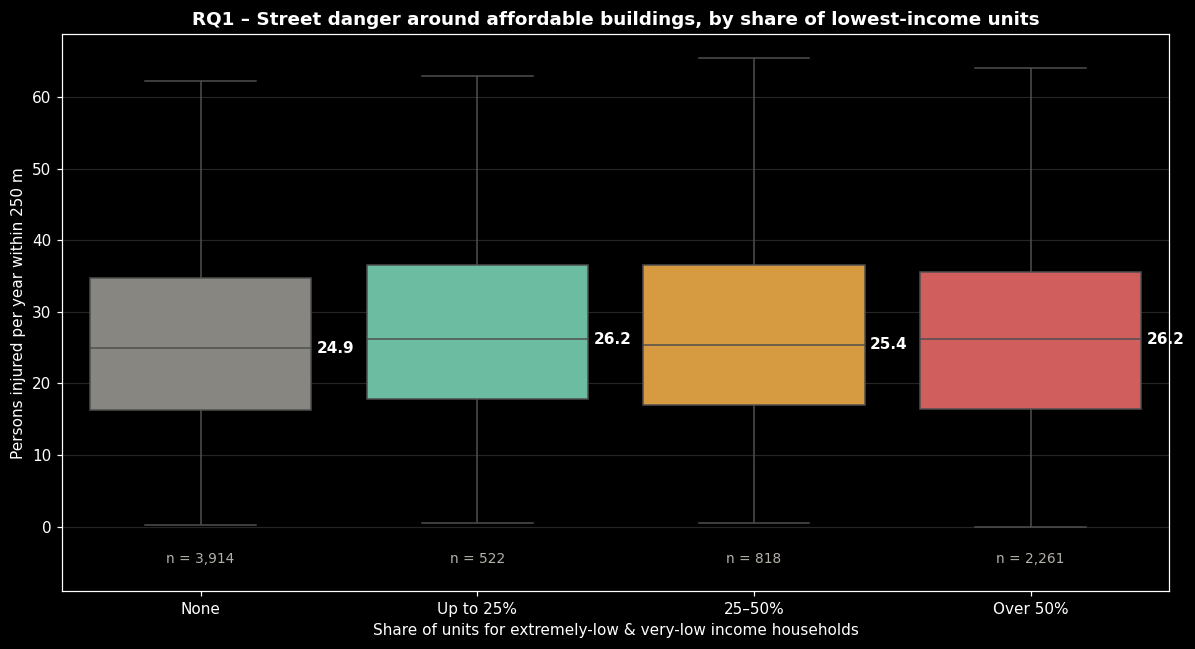

Box = Q1–Q3, line = median; whiskers = 1.5 × IQR; outliers hidden for readability (they are real values, see Section 6).


In [ ]:
# ---------- RQ1: lowest-income share vs. street danger ----------
rq1 = sites.dropna(subset=['lowest_income_share']).copy()
rq1['lowest_income_group'] = pd.cut(rq1['lowest_income_share'],
                                    bins=[-0.001, 0, 0.25, 0.5, 1.0],
                                    labels=['None', 'Up to 25%', '25–50%', 'Over 50%'])
GROUPS = rq1['lowest_income_group'].cat.categories.tolist()

# --- Five-number summary per group (Lecture 3) ---
summary = five_number_summary(rq1, 'lowest_income_group', 'injured_250m_per_year')
print('Persons injured per year within 250 m – five-number summary by lowest-income share:')
display(summary)

# --- Borough control: medians within each borough ---
print('Median injuries/year within 250 m – WITHIN each borough:')
display(rq1.pivot_table(index='borough', columns='lowest_income_group', values='injured_250m_per_year',
                        aggfunc='median', observed=True).reindex(BOROUGH_ORDER).round(1))

# --- Chart: box plot (Lecture 4) ---
fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=rq1, x='lowest_income_group', y='injured_250m_per_year', order=GROUPS,
            palette=['#888780', '#5DCAA5', '#EF9F27', '#E24B4A'], showfliers=False, ax=ax)
for i, group in enumerate(GROUPS):
    med = summary.loc[group, 'median']
    ax.text(i + 0.42, med, f'{med:.1f}', va='center', ha='left', fontsize=10, fontweight='bold', color='white')
    ax.text(i, -5, f'n = {summary.loc[group, "n"]:,.0f}', ha='center', fontsize=9, color='#B4B2A9')
ax.set(title='RQ1 – Street danger around affordable buildings, by share of lowest-income units',
       xlabel='Share of units for extremely-low & very-low income households',
       ylabel='Persons injured per year within 250 m')
ax.set_ylim(bottom=-9)
plt.tight_layout()
plt.show()
print('Box = Q1–Q3, line = median; whiskers = 1.5 × IQR; outliers hidden for readability (they are real values, see Section 6).')

### RQ2 – Does street danger change after a building opens? *(Ziad Moharam)*

**Why it matters:** new buildings bring residents, deliveries and visitors. Planners need to know whether streets around new affordable housing become more dangerous once people move in, and whether that differs for **new construction** (new residents arrive) and **preservation** (existing residents stay).

**Method**
- Buildings completed **2017–2024** with a reliable baseline (≥ 10 crashes / injuries in the year before; Section 8).
- Measure = **change vs. city**: change in crashes / injuries within 250 m in the 12 months after vs. before completion, **relative to the citywide change** over the same months (Section 7.3). 0% = the same as the city.
- Groups: **construction type** × **building size** (small ≤ 20 units, medium 21–100, large > 100).
- **Median** change per group (robust to the skewed ratios), plus Q1, Q3 and the **share of buildings that got worse than the city** (change > 0).
- **Grouped bar chart** (Lecture 4: comparing sub-categories within main categories), one panel each for crashes and injuries, with a reference line at 0%.

,measure,construction,size,buildings,Q1 %,median %,Q3 %,worse than city
0,Crashes,New Construction,Small (≤20),1005,-15.1,-0.3,16.0,49.4
1,Injuries,New Construction,Small (≤20),919,-25.0,-5.3,21.8,43.2
2,Crashes,New Construction,Medium (21–100),651,-14.5,-1.5,14.4,46.9
3,Injuries,New Construction,Medium (21–100),594,-26.3,-4.9,21.9,43.9
4,Crashes,New Construction,Large (>100),359,-10.4,-0.1,14.9,49.9
5,Injuries,New Construction,Large (>100),306,-20.8,0.7,23.6,50.7
6,Crashes,Preservation,Small (≤20),1387,-9.8,2.9,13.2,56.7
7,Injuries,Preservation,Small (≤20),1301,-24.8,-5.0,19.7,43.1
8,Crashes,Preservation,Medium (21–100),629,-10.7,2.8,15.4,54.4
9,Injuries,Preservation,Medium (21–100),576,-22.1,0.9,32.5,51.6


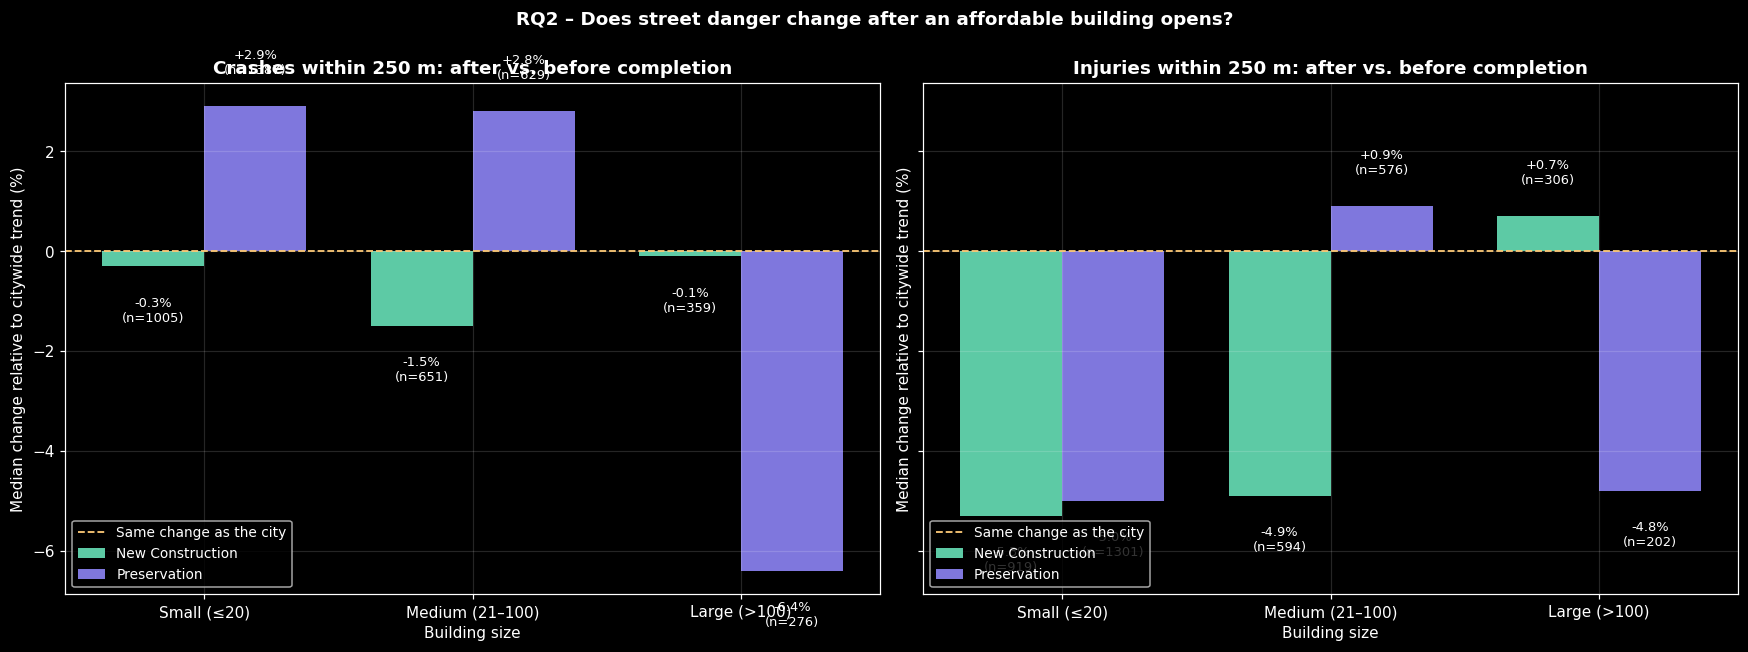

In [ ]:
# ---------- RQ2: before vs. after completion, relative to the city ----------
rq2 = sites.dropna(subset=['crash_change_vs_city']).copy()
rq2['size_group'] = pd.cut(rq2['total_units'], bins=[0, 20, 100, np.inf],
                           labels=['Small (≤20)', 'Medium (21–100)', 'Large (>100)'])
SIZE_ORDER = rq2['size_group'].cat.categories.tolist()
MEASURES = {'Crashes': 'crash_change_vs_city', 'Injuries': 'injured_change_vs_city'}

# --- Summary per group: median, quartiles, share worse than the city ---
rows = []
for (ctype, size), g in rq2.groupby(['reporting_construction_type', 'size_group'], observed=True):
    for measure, col in MEASURES.items():
        v = g[col].dropna() * 100
        rows.append({'measure': measure, 'construction': ctype, 'size': size, 'buildings': len(v),
                     'Q1 %': v.quantile(0.25), 'median %': v.median(), 'Q3 %': v.quantile(0.75),
                     'worse than city': (v > 0).mean() * 100})
rq2_summary = pd.DataFrame(rows).round(1)
display(rq2_summary)

# --- Chart: grouped bar of median change (Lecture 4) ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
colors = {'New Construction': '#5DCAA5', 'Preservation': '#7F77DD'}
width = 0.38
x = np.arange(len(SIZE_ORDER))

for ax, measure in zip(axes, MEASURES):
    data = rq2_summary[rq2_summary['measure'] == measure]
    for i, ctype in enumerate(['New Construction', 'Preservation']):
        d = data[data['construction'] == ctype].set_index('size').reindex(SIZE_ORDER)
        bars = ax.bar(x + (i - 0.5) * width, d['median %'], width, color=colors[ctype], label=ctype)
        for bar, med, n in zip(bars, d['median %'], d['buildings']):
            if pd.notna(med):
                y = med + (0.6 if med >= 0 else -0.6)
                ax.text(bar.get_x() + bar.get_width() / 2, y, f'{med:+.1f}%\n(n={n:.0f})',
                        ha='center', va='bottom' if med >= 0 else 'top', fontsize=8.5, color='white')
    ax.axhline(0, color='#FAC775', ls='--', lw=1.2, label='Same change as the city')
    ax.set_xticks(x, SIZE_ORDER)
    ax.set(title=f'{measure} within 250 m: after vs. before completion',
           xlabel='Building size', ylabel='Median change relative to citywide trend (%)')
    ax.legend(fontsize=9, loc='lower left')

fig.suptitle('RQ2 – Does street danger change after an affordable building opens?', fontweight='bold')
plt.tight_layout()
plt.show()



---




### RQ3 – Where do affordable housing and dangerous streets overlap? *(Youssef Ahmed)*

**Why it matters:** a single map shows planners and residents *where* the problem is concentrated, so street-safety budgets can be targeted at the affordable-housing clusters with the most injuries around them.

**Method**
- Every unique building site is placed at its coordinates (**map**, Lecture 3: visualizing a distribution in space).
- **Colour = danger level** (quintiles of injuries within 250 m per year; Section 8). This is an **ordinal** attribute, so a **sequential** colour scheme is used (light = low, dark/red = high, Lecture 5).
- **Size = number of units**, so large developments stand out.
- A table gives the **share of affordable units in each danger level per borough**.

Share of affordable units (%) in each danger level, by borough:


danger_level,Very low,Low,Medium,High,Very high
borough,,,,,
Bronx,24.6,18.7,17.8,17.8,21.1
Brooklyn,24.7,18.2,16.2,18.1,22.7
Manhattan,16.1,21.6,17.7,20.3,24.3
Queens,60.4,10.6,8.1,13.3,7.6
Staten Island,98.0,2.0,0.0,0.0,0.0


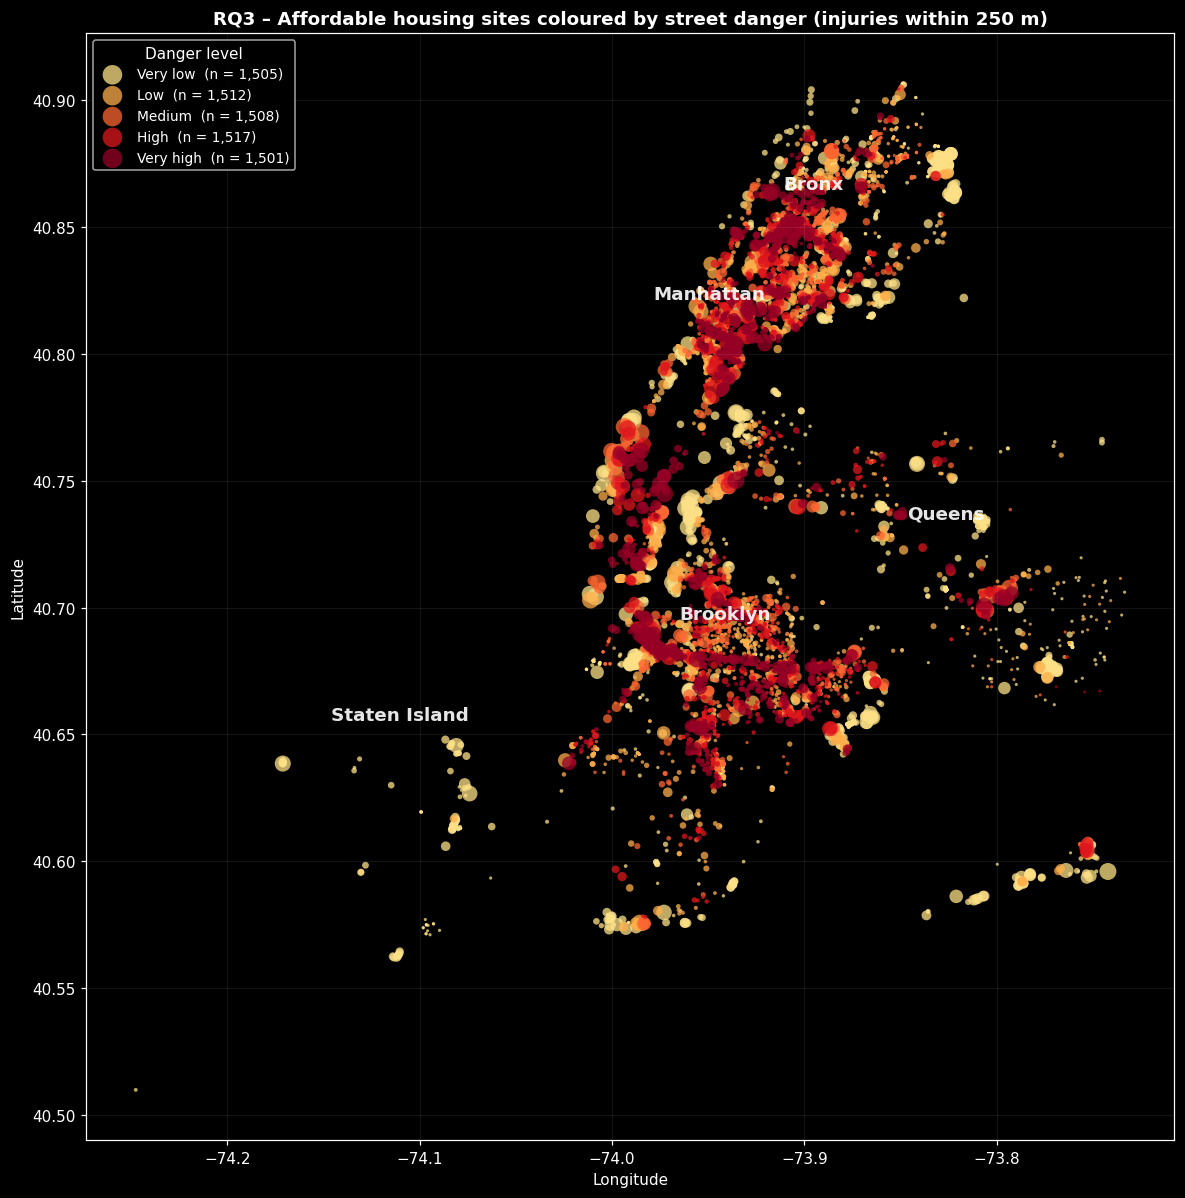

Bubble size = total units in the building. Danger levels are quintiles over all buildings (each level holds 20% of buildings citywide).


In [ ]:
# ---------- RQ3: map of affordable housing coloured by street danger ----------
rq3 = sites.copy()
rq3['danger_level'] = pd.Categorical(rq3['danger_level'], categories=DANGER_ORDER, ordered=True)

# Sequential scheme (Lecture 5): light yellow = very low danger -> dark red = very high danger
DANGER_COLORS = {lvl: plt.cm.YlOrRd(v) for lvl, v in zip(DANGER_ORDER, np.linspace(0.2, 0.95, 5))}

# --- Table: share of affordable units in each danger level, per borough ---
unit_share = pd.crosstab(rq3['borough'].astype(str), rq3['danger_level'],
                         values=rq3['all_counted_units'], aggfunc='sum', normalize='index') * 100
print('Share of affordable units (%) in each danger level, by borough:')
display(unit_share.reindex(BOROUGH_ORDER).round(1))

# --- Map ---
fig, ax = plt.subplots(figsize=(11, 11))
for lvl in DANGER_ORDER:
    d = rq3[rq3['danger_level'] == lvl]
    ax.scatter(d['longitude'], d['latitude'], s=np.clip(d['total_units'], 1, 600) / 5 + 4,
               color=DANGER_COLORS[lvl], alpha=0.75, edgecolors='none',
               label=f'{lvl}  (n = {len(d):,})')

# Borough labels at the median position of their buildings
for borough, g in rq3.groupby(rq3['borough'].astype(str)):
    ax.text(g['longitude'].median(), g['latitude'].median() + 0.02, borough,
            fontsize=12, fontweight='bold', color='white', ha='center', alpha=0.9)

ax.set_aspect(1 / np.cos(np.radians(40.7)))      # correct east-west stretch at NYC's latitude
ax.set(title='RQ3 – Affordable housing sites coloured by street danger (injuries within 250 m)',
       xlabel='Longitude', ylabel='Latitude')
ax.legend(title='Danger level', markerscale=1.6, loc='upper left', fontsize=9)
ax.grid(alpha=0.08)
plt.tight_layout()
plt.show()
print('Bubble size = total units in the building. Danger levels are quintiles over all buildings '
      '(each level holds 20% of buildings citywide).')

### RQ4 – Is the city building more of its new affordable housing in dangerous areas over time? *(Youssef Ahmed)*

**Why it matters:** RQ3 shows *where* housing is. RQ4 asks whether recent decisions are making things better or worse: is a growing share of each year's new affordable units being placed next to the city's most dangerous streets?

**Method**
- Buildings completed **2016–2025**, grouped by **borough × completion year**.
- Value = **% of affordable units completed that year in a *High* or *Very high* danger area** (top 40% of sites by injuries within 250 m).
- **Reference:** because the danger levels are quintiles, **40%** is the "fair share". Above 40% means more housing than expected went to dangerous areas.
- **Heatmap** (Lecture 5) with a **sequential** colour scale; cells with fewer than 50 units completed are left blank, because a percentage of a handful of units is not reliable.

Affordable units completed (denominator of each cell):


completion_year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
borough,,,,,,,,,,
Bronx,2805,6694,6299,8591,3672,5539,11452,17011,9184,6968
Brooklyn,4799,6067,10790,4233,4438,4698,3387,6909,4910,5948
Manhattan,3419,5174,7253,7193,3563,3543,2687,3694,5953,4851
Queens,1247,2855,874,1033,480,3686,3381,2515,2263,7577
Staten Island,714,116,1053,0,131,148,364,67,40,30
All NYC,12984,20906,26269,21050,12284,17614,21271,30196,22350,25374


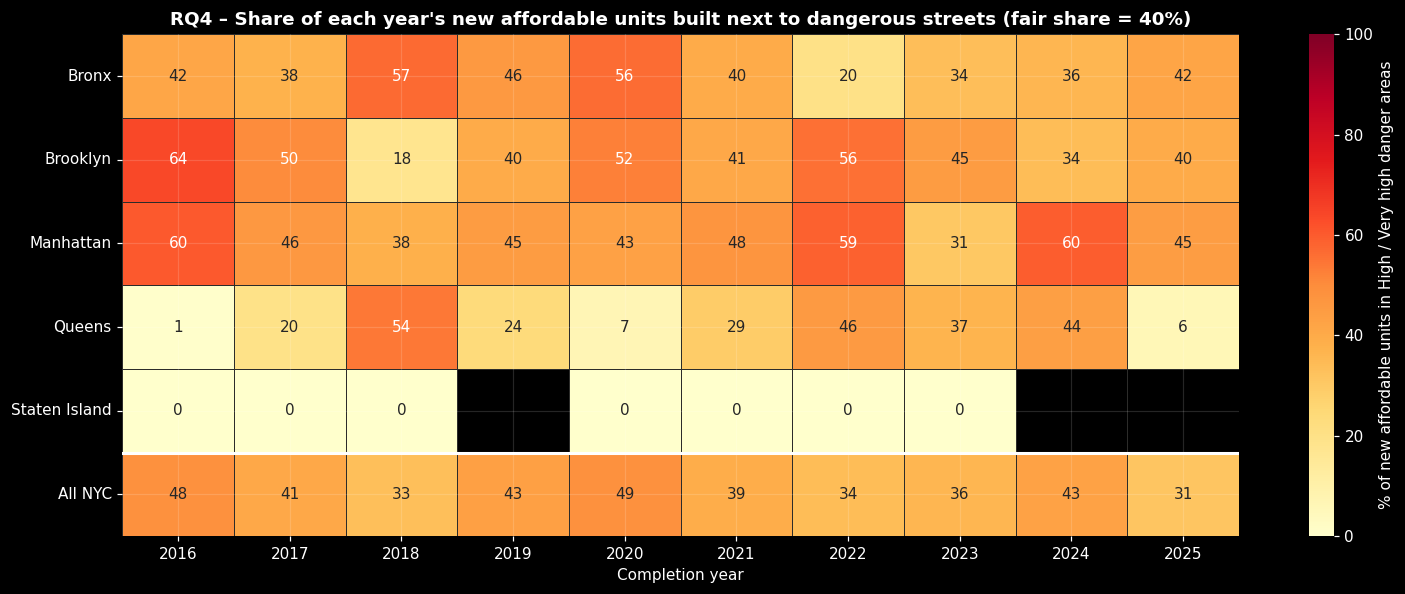

Blank cells: fewer than 50 affordable units completed that year (percentage not reliable).


In [ ]:
# ---------- RQ4: share of new affordable units placed in dangerous areas, by borough and year ----------
rq4 = sites[sites['completion_year'].between(2016, 2025)].copy()
rq4['completion_year'] = rq4['completion_year'].astype(int)
rq4['borough'] = rq4['borough'].astype(str)
rq4['dangerous_units'] = rq4['all_counted_units'].where(rq4['danger_level'].isin(['High', 'Very high']), 0)

by_borough = rq4.groupby(['borough', 'completion_year'])[['dangerous_units', 'all_counted_units']].sum()
citywide = rq4.groupby('completion_year')[['dangerous_units', 'all_counted_units']].sum()
citywide.index = pd.MultiIndex.from_product([['All NYC'], citywide.index], names=['borough', 'completion_year'])
combined = pd.concat([by_borough, citywide])

ROW_ORDER = BOROUGH_ORDER + ['All NYC']
share = (combined['dangerous_units'] / combined['all_counted_units'] * 100).unstack('completion_year').reindex(ROW_ORDER)
units = combined['all_counted_units'].unstack('completion_year').reindex(ROW_ORDER).fillna(0)

print('Affordable units completed (denominator of each cell):')
display(units.astype(int))

# --- Heatmap (Lecture 5) ---
fig, ax = plt.subplots(figsize=(14, 5.5))
sns.heatmap(share, mask=units < 50, annot=True, fmt='.0f', cmap='YlOrRd', vmin=0, vmax=100,
            linewidths=0.5, linecolor='#2C2C2A',
            cbar_kws={'label': '% of new affordable units in High / Very high danger areas'}, ax=ax)
ax.axhline(len(BOROUGH_ORDER), color='white', lw=2)            # separate the citywide row
ax.set(title='RQ4 – Share of each year\'s new affordable units built next to dangerous streets '
             '(fair share = 40%)', xlabel='Completion year', ylabel='')
plt.tight_layout()
plt.show()
print('Blank cells: fewer than 50 affordable units completed that year (percentage not reliable).')



---



### RQ5 – Which income groups carry the most street danger? *(Hana Ahmed)*

**Why it matters:** RQ1 compares *buildings*; RQ5 counts *households*. A building can mix income groups, so here every affordable **unit** is assigned to its income band, revealing which income groups live closest to the most dangerous streets.

**Method**
- Income bands (**ordinal**, Lecture 2): Extremely low < Very low < Low < Moderate < Middle.
- Unit counts per band come from the cleaned housing table and are joined to the building-level danger level using `project_id` + `building_id`.
- For each band: **% of its units in each danger level**.
- **100% stacked horizontal bar chart** (Lecture 4: composition of categories; horizontal for long labels), coloured with the same sequential danger scale as RQ3.

Affordable units per income band and danger level:


danger_level,Very low,Low,Medium,High,Very high,Total
Extremely low,13291,11130,9355,11208,13382,58366
Very low,33403,13956,12142,13209,12558,85268
Low,28439,18911,17741,19673,22252,107016
Moderate,4772,3819,2890,2843,4557,18881
Middle,10863,8401,7326,8198,10466,45254


Share of each band in High + Very high danger areas (%):


,High + Very high %
Extremely low,42.1
Very low,30.2
Low,39.2
Moderate,39.2
Middle,41.2


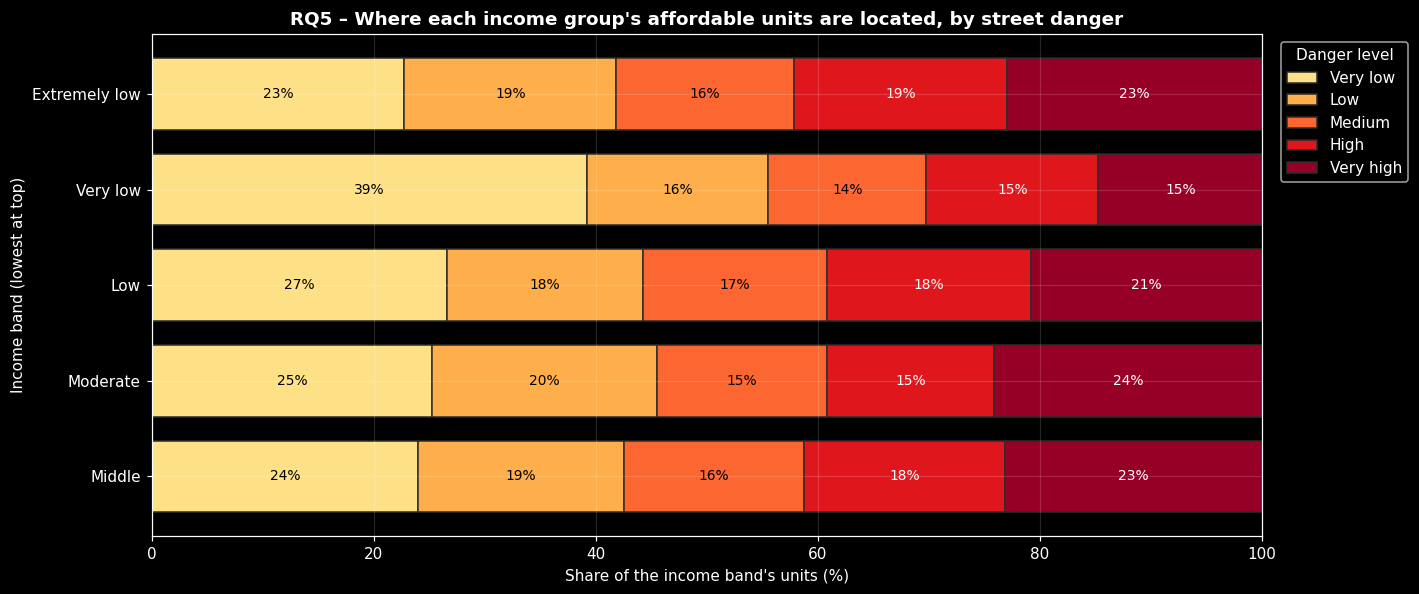

In [ ]:
# ---------- RQ5: distribution of each income band's units across danger levels ----------
INCOME_BANDS = {'extremely_low_income_units': 'Extremely low', 'very_low_income_units': 'Very low',
                'low_income_units': 'Low', 'moderate_income_units': 'Moderate',
                'middle_income_units': 'Middle'}

rq5 = (sites.dropna(subset=['building_id'])[['project_id', 'building_id', 'danger_level']]
       .merge(housing[['project_id', 'building_id'] + list(INCOME_BANDS)],
              on=['project_id', 'building_id'], how='left', validate='many_to_one'))
rq5['danger_level'] = pd.Categorical(rq5['danger_level'], categories=DANGER_ORDER, ordered=True)

units_by_level = rq5.groupby('danger_level', observed=False)[list(INCOME_BANDS)].sum().T
units_by_level.index = units_by_level.index.map(INCOME_BANDS)
share = units_by_level.div(units_by_level.sum(axis=1), axis=0) * 100

print('Affordable units per income band and danger level:')
display(units_by_level.assign(Total=units_by_level.sum(axis=1)).astype(int))
print('Share of each band in High + Very high danger areas (%):')
display((share['High'] + share['Very high']).round(1).rename('High + Very high %').to_frame())

# --- 100% stacked horizontal bar (Lecture 4) ---
fig, ax = plt.subplots(figsize=(13, 5.5))
share.plot(kind='barh', stacked=True, color=[DANGER_COLORS[l] for l in DANGER_ORDER],
           width=0.75, ax=ax, edgecolor='#2C2C2A')
for container, lvl in zip(ax.containers, DANGER_ORDER):
    labels = [f'{w:.0f}%' if w >= 5 else '' for w in container.datavalues]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=9,
                 color='black' if lvl in ['Very low', 'Low', 'Medium'] else 'white')
ax.invert_yaxis()                                     # lowest income band on top
ax.set(title='RQ5 – Where each income group\'s affordable units are located, by street danger',
       xlabel='Share of the income band\'s units (%)', ylabel='Income band (lowest at top)', xlim=(0, 100))
ax.legend(title='Danger level', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

### RQ6 – Do neighbourhoods receiving new housing have a higher pedestrian share of injuries? *(Hana Ahmed)*

**Why it matters:** residents of affordable housing walk more. If, in ZIPs where new affordable housing is completed, a larger share of traffic injuries hit **pedestrians**, then safety measures there should prioritise crossings, sidewalks and speed control, not just car traffic.

**Method**
- Regular ZIP-years with at least one injury.
- Two groups: ZIP-years **with** vs. **without** affordable housing completed that year.
- Measure = **pedestrian share** = pedestrians injured ÷ all persons injured.
- **Histogram** (Lecture 4: shape of a continuous distribution) for both groups, normalised to % so the different group sizes are comparable, with the **medians** marked.
- **Borough control:** medians compared within each borough, because Manhattan has both very high pedestrian shares and its own housing pattern.

Pedestrian share of injuries (%) – five-number summary:


,n,min,Q1,median,Q3,max,IQR
group,,,,,,,
With new affordable housing,853,4.2,15.1,19.0,23.5,43.0,8.4
Without new affordable housing,993,0.0,10.9,16.9,24.7,100.0,13.8


Median pedestrian share (%) WITHIN each borough:


group,With new affordable housing,Without new affordable housing
borough,,
Bronx,17.8,13.2
Brooklyn,18.4,18.9
Manhattan,24.2,25.8
Queens,16.5,12.8
Staten Island,15.1,14.5


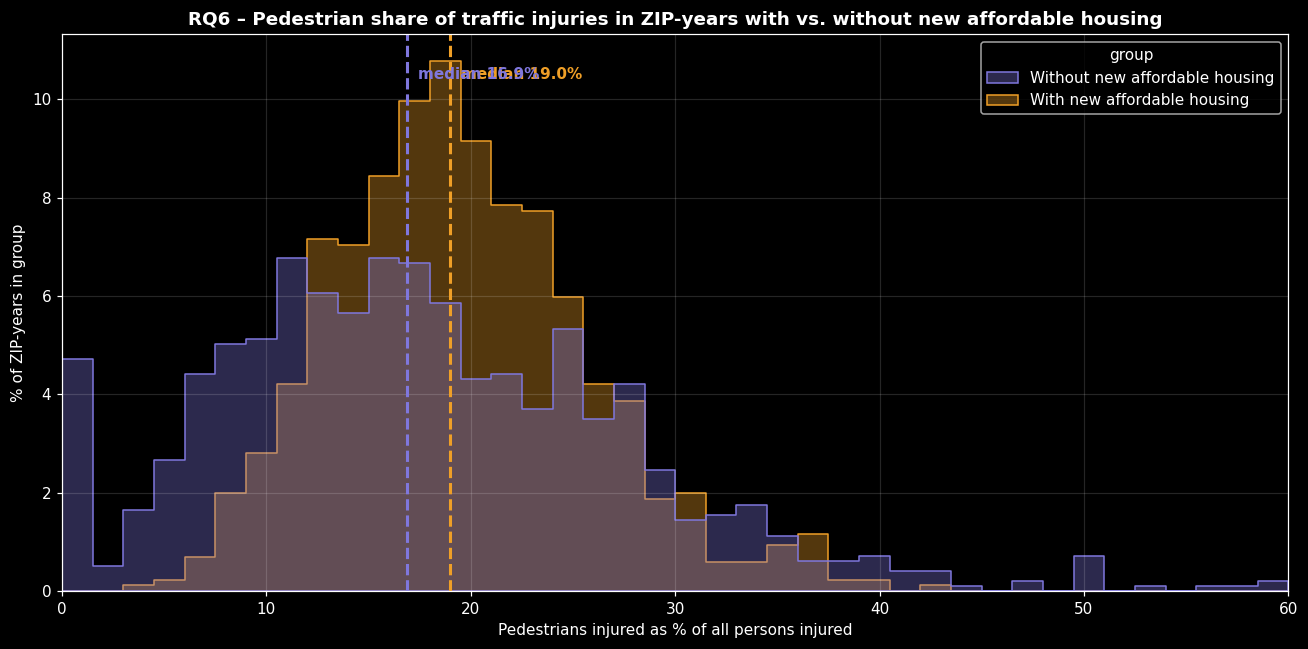

x-axis limited to 0–60% (covers almost all ZIP-years); summaries use all values.


In [ ]:
# ---------- RQ6: pedestrian share of injuries, ZIP-years with vs. without new housing ----------
rq6 = regular_zips[regular_zips['persons_injured'] > 0].copy()
rq6['pedestrian_pct'] = rq6['pedestrian_share'] * 100
rq6['group'] = np.where(rq6['has_new_housing'], 'With new affordable housing', 'Without new affordable housing')
GROUP_COLORS = {'With new affordable housing': '#EF9F27', 'Without new affordable housing': '#7F77DD'}

print('Pedestrian share of injuries (%) – five-number summary:')
display(five_number_summary(rq6, 'group', 'pedestrian_pct'))
print('Median pedestrian share (%) WITHIN each borough:')
display(rq6.pivot_table(index=rq6['borough'].astype(str), columns='group', values='pedestrian_pct',
                        aggfunc='median').reindex(BOROUGH_ORDER).round(1))

# --- Histogram (Lecture 4) ---
fig, ax = plt.subplots(figsize=(12, 6))
sns.histplot(data=rq6, x='pedestrian_pct', hue='group', bins=40, binrange=(0, 60),
             stat='percent', common_norm=False, element='step', fill=True, alpha=0.35,
             palette=GROUP_COLORS, ax=ax)
for group, color in GROUP_COLORS.items():
    med = rq6.loc[rq6['group'] == group, 'pedestrian_pct'].median()
    ax.axvline(med, color=color, ls='--', lw=2)
    ax.text(med + 0.5, ax.get_ylim()[1] * (0.92 if 'With' in group else 0.84),
            f'median {med:.1f}%', color=color, fontsize=10, fontweight='bold')
ax.set(title='RQ6 – Pedestrian share of traffic injuries in ZIP-years with vs. without new affordable housing',
       xlabel='Pedestrians injured as % of all persons injured', ylabel='% of ZIP-years in group',
       xlim=(0, 60))
plt.tight_layout()
plt.show()
print('x-axis limited to 0–60% (covers almost all ZIP-years); summaries use all values.')



---



### RQ7 – Do ZIPs with more cumulative affordable housing rank higher for injuries? *(Mostafa Abuelabbas)*

**Why it matters:** this is the city-wide view of our theme. If the ZIPs that absorbed the most affordable housing since 2014 are also the ZIPs with the most traffic injuries year after year, affordable-housing residents are systematically more exposed.

**Method**
- One point per regular ZIP.
- **x = affordable units completed 2014–2025** (cumulative stock). Shown on a **log scale**, because a few ZIPs received thousands of units (skewed, Lecture 3).
- **y = average injury percentile** across 2016–2025 (`injury_rank_in_year`): 0 = fewest injuries in that year, 1 = most. Ranking within each year removes the citywide downward trend.
- **Scatter plot + linear trend line + correlation coefficient r** (Lecture 4: relationship between two numeric variables), overall and per borough.
- **Limitation:** there is no population column, so ZIPs with more people may have both more housing and more injuries; *r* shows association only.

ZIPs: 185 | with affordable housing: 145
Correlation r (log stock vs. mean injury rank), all ZIPs: 0.56

Correlation r within each borough:


,r
Bronx,0.61
Brooklyn,0.21
Manhattan,0.74
Queens,0.45
Staten Island,0.21


Mean injury rank: ZIPs without vs. with affordable housing


,size,mean,median
affordable_stock,,,
No housing,40,0.223,0.150
Has housing,145,0.580,0.595


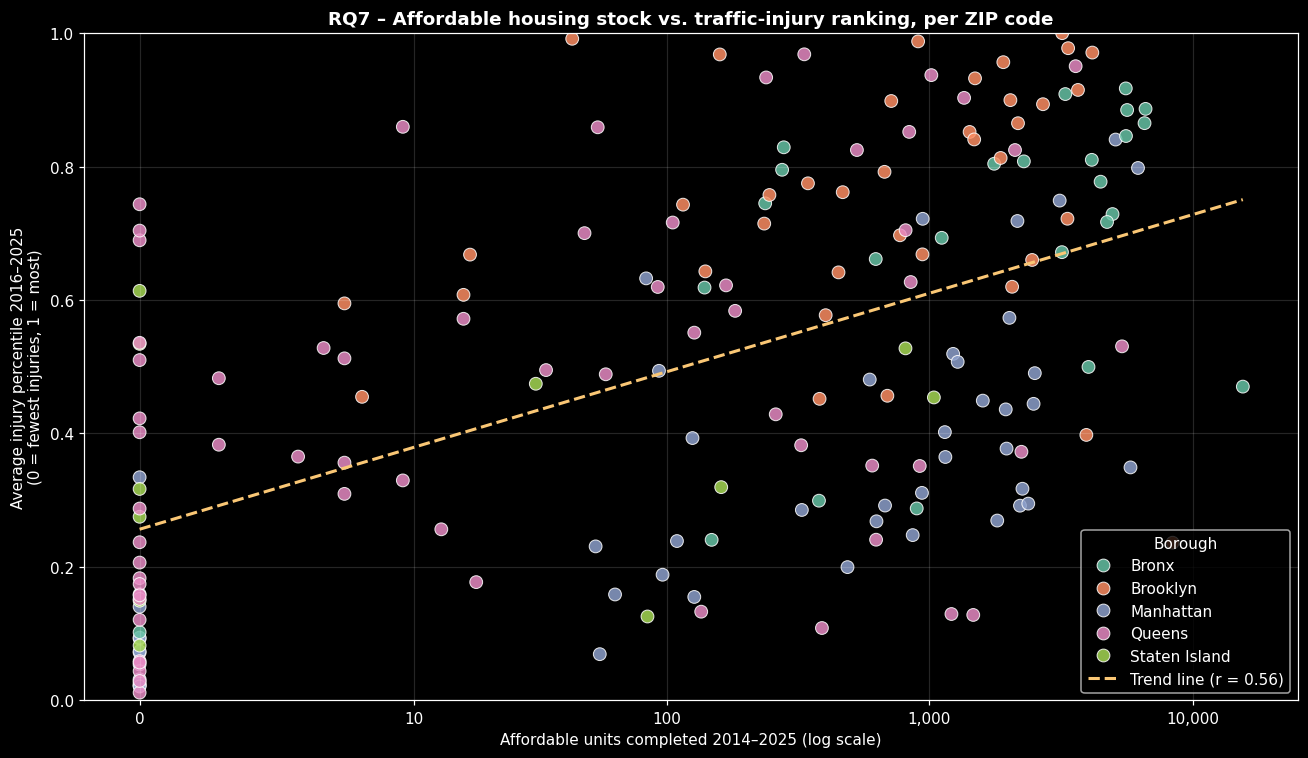

In [ ]:
# ---------- RQ7: cumulative affordable stock vs. average injury rank, per ZIP ----------
zip_level = (regular_zips.groupby('zip_code')
             .agg(borough=('borough', 'first'),
                  affordable_stock=('affordable_units_cumulative', 'max'),
                  mean_injury_rank=('injury_rank_in_year', 'mean'))
             .reset_index())
zip_level['borough'] = zip_level['borough'].astype(str)
zip_level['log_stock'] = np.log10(zip_level['affordable_stock'] + 1)

r_all = np.corrcoef(zip_level['log_stock'], zip_level['mean_injury_rank'])[0, 1]
print(f'ZIPs: {len(zip_level)} | with affordable housing: {(zip_level["affordable_stock"] > 0).sum()}')
print(f'Correlation r (log stock vs. mean injury rank), all ZIPs: {r_all:.2f}\n')

per_borough = {b: np.corrcoef(g['log_stock'], g['mean_injury_rank'])[0, 1]
               for b, g in zip_level.groupby('borough') if len(g) >= 5}
print('Correlation r within each borough:')
display(pd.Series(per_borough, name='r').round(2).reindex(BOROUGH_ORDER).to_frame())

print('Mean injury rank: ZIPs without vs. with affordable housing')
display(zip_level.groupby(zip_level['affordable_stock'] > 0)['mean_injury_rank']
        .agg(['size', 'mean', 'median']).rename(index={False: 'No housing', True: 'Has housing'}).round(3))

# --- Scatter + trend line (Lecture 4) ---
fig, ax = plt.subplots(figsize=(12, 7))
sns.scatterplot(data=zip_level, x='log_stock', y='mean_injury_rank', hue='borough',
                hue_order=BOROUGH_ORDER, palette='Set2', s=70, alpha=0.85, ax=ax)
slope, intercept = np.polyfit(zip_level['log_stock'], zip_level['mean_injury_rank'], 1)
xs = np.linspace(0, zip_level['log_stock'].max(), 100)
ax.plot(xs, slope * xs + intercept, color='#FAC775', lw=2, ls='--', label=f'Trend line (r = {r_all:.2f})')

ticks = [0, 10, 100, 1000, 10000]
ax.set_xticks(np.log10(np.array(ticks) + 1), [f'{t:,}' for t in ticks])
ax.set(title='RQ7 – Affordable housing stock vs. traffic-injury ranking, per ZIP code',
       xlabel='Affordable units completed 2014–2025 (log scale)',
       ylabel='Average injury percentile 2016–2025\n(0 = fewest injuries, 1 = most)', ylim=(0, 1))
ax.legend(title='Borough', loc='lower right')
plt.tight_layout()
plt.show()

### RQ8 – Can a wave of completions predict a change in injuries? *(Mostafa Abuelabbas)*

**Why it matters:** if injuries in a ZIP tend to **rise in the years after** a large batch of affordable units opens, the city could schedule street-safety work *before* move-in instead of reacting afterwards. This is a **lag analysis**: we look at what happens *around* an event in time.

**Method**
- For each regular ZIP, its **event year** = the year with the most affordable units completed (only if ≥ 100 units, and in 2018–2023, so that 2 years before and after are inside the data).
- Each ZIP's **injury percentile** (`injury_rank_in_year`) is lined up from **2 years before** to **2 years after** its event year (relative years –2 … +2). Using the within-year percentile removes the citywide trend.
- **Line chart** (Lecture 4: change over time) of the **median** percentile, with Q1 and Q3 as thin lines to show spread.
- Also: the share of ZIPs whose percentile **rose** from year –2 to year +2.

ZIPs with a completion wave (≥ 100 units, 2018–2023): 60


,ZIPs,Q1,median,Q3
relative_year,,,,
-2,60,0.395,0.693,0.879
-1,60,0.432,0.682,0.854
0,60,0.403,0.664,0.832
1,60,0.376,0.694,0.829
2,60,0.399,0.649,0.860


ZIPs whose injury percentile rose from year –2 to year +2: 45% (median change: -0.010)


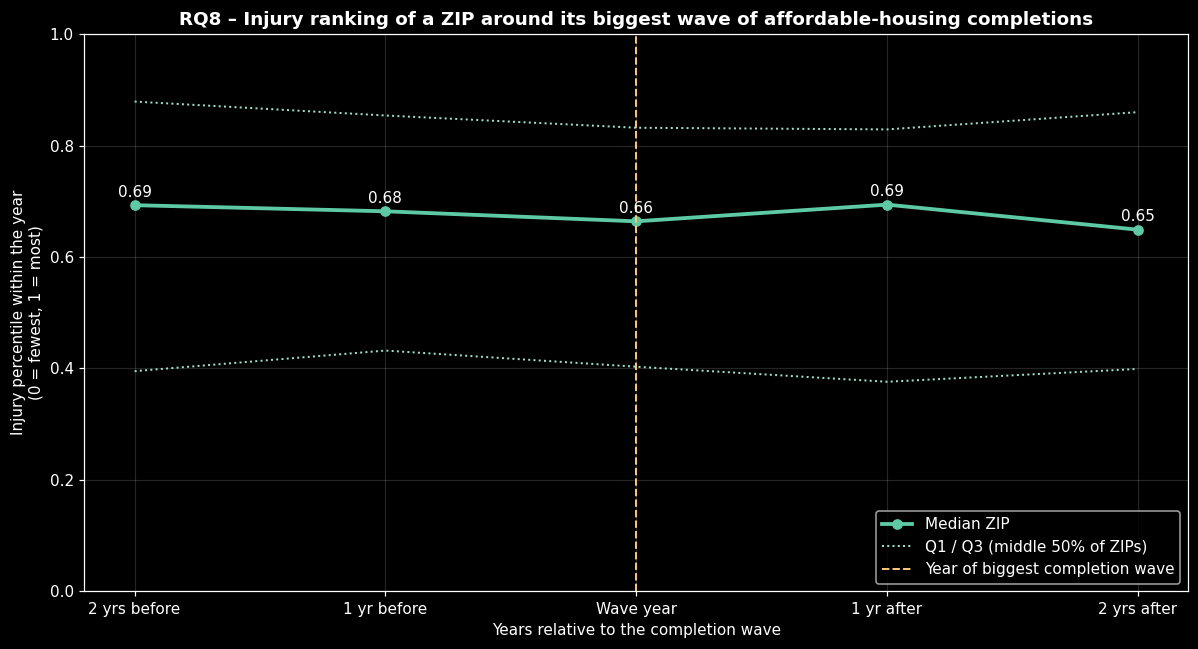

In [ ]:
# ---------- RQ8: injury rank around each ZIP's biggest completion year ----------
EVENT_MIN_UNITS = 100

peak = (regular_zips.sort_values('affordable_units_completed', ascending=False)
        .drop_duplicates('zip_code')[['zip_code', 'year', 'affordable_units_completed']]
        .rename(columns={'year': 'event_year', 'affordable_units_completed': 'event_units'}))
peak = peak[(peak['event_units'] >= EVENT_MIN_UNITS) & peak['event_year'].between(2018, 2023)]

panel = regular_zips.merge(peak, on='zip_code')
panel['relative_year'] = panel['year'].astype(int) - panel['event_year'].astype(int)
panel = panel[panel['relative_year'].between(-2, 2)]

line = panel.groupby('relative_year')['injury_rank_in_year'].agg(
    ZIPs='size', Q1=lambda s: s.quantile(0.25), median='median', Q3=lambda s: s.quantile(0.75)).round(3)
print(f'ZIPs with a completion wave (≥ {EVENT_MIN_UNITS} units, 2018–2023): {peak["zip_code"].nunique()}')
display(line)

wide = panel.pivot_table(index='zip_code', columns='relative_year', values='injury_rank_in_year')
rose = (wide[2] > wide[-2]).mean() * 100
print(f'ZIPs whose injury percentile rose from year –2 to year +2: {rose:.0f}% '
      f'(median change: {(wide[2] - wide[-2]).median():+.3f})')

# --- Line chart (Lecture 4) ---
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(line.index, line['median'], marker='o', lw=2.5, color='#5DCAA5', label='Median ZIP')
ax.plot(line.index, line['Q1'], ls=':', lw=1.3, color='#9FE1CB', label='Q1 / Q3 (middle 50% of ZIPs)')
ax.plot(line.index, line['Q3'], ls=':', lw=1.3, color='#9FE1CB')
ax.axvline(0, color='#FAC775', ls='--', lw=1.3, label='Year of biggest completion wave')
for x, y in zip(line.index, line['median']):
    ax.text(x, y + 0.015, f'{y:.2f}', ha='center', fontsize=10, color='white')
ax.set_xticks([-2, -1, 0, 1, 2], ['2 yrs before', '1 yr before', 'Wave year', '1 yr after', '2 yrs after'])
ax.set(title='RQ8 – Injury ranking of a ZIP around its biggest wave of affordable-housing completions',
       xlabel='Years relative to the completion wave',
       ylabel='Injury percentile within the year\n(0 = fewest, 1 = most)', ylim=(0, 1))
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()



---



### RQ9 – Did injuries fall more slowly where the most housing was built? *(Hazem Ahmed)*

**Why it matters:** traffic injuries fell across NYC since 2016. If neighbourhoods that absorbed the most new affordable housing were **left behind** by that improvement, their residents did not share equally in the city's safety gains.

**Method**
- Regular ZIPs split by affordable units completed 2014–2025: **No new housing**, **Some housing**, **Most housing** (top 25% of ZIPs that received housing).
- Persons injured per group per year, **indexed to 2016 = 100**. Indexing compares the *speed of change*, not size: big groups and small groups start at the same point.
- **Multi-line chart** (Lecture 4: trends, comparing groups; 3 lines, within the 4–5 line limit), with 2020 (COVID-19) shaded.

"Most housing" threshold: ≥ 2,161 affordable units completed 2014–2025


,ZIPs,median units
No new housing,40,0.0
Some housing,108,339.5
Most housing (top 25%),37,3671.0


Persons injured, indexed (2016 = 100):


housing_group,No new housing,Some housing,Most housing (top 25%)
year,,,
2016,100.0,100.0,100.0
2017,116.1,104.7,104.9
2018,112.3,107.0,105.9
2019,110.5,103.9,102.0
2020,71.9,72.8,83.6
2021,78.3,86.1,95.0
2022,80.4,86.5,91.1
2023,89.5,91.9,92.8
2024,95.0,91.7,87.2


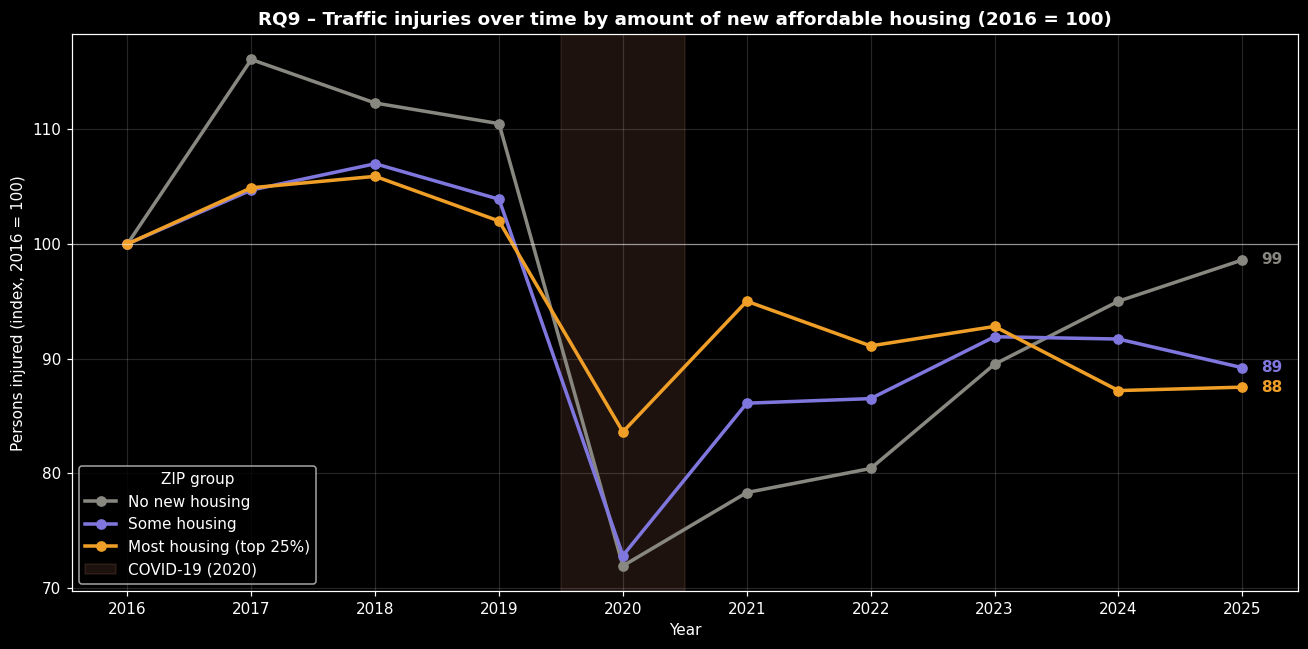

In [ ]:
# ---------- RQ9: injury trend (2016 = 100) by amount of new affordable housing ----------
stock = regular_zips.groupby('zip_code')['affordable_units_cumulative'].max()
top_cut = stock[stock > 0].quantile(0.75)
zip_group = pd.Series(np.select([stock == 0, stock >= top_cut],
                                ['No new housing', 'Most housing (top 25%)'], 'Some housing'),
                      index=stock.index)
GROUP_ORDER = ['No new housing', 'Some housing', 'Most housing (top 25%)']
GROUP_COLORS9 = dict(zip(GROUP_ORDER, ['#888780', '#7F77DD', '#EF9F27']))

print(f'"Most housing" threshold: ≥ {top_cut:,.0f} affordable units completed 2014–2025')
display(pd.DataFrame({'ZIPs': zip_group.value_counts(),
                      'median units': stock.groupby(zip_group).median()}).reindex(GROUP_ORDER))

rq9 = regular_zips.assign(housing_group=regular_zips['zip_code'].map(zip_group))
yearly = rq9.groupby(['year', 'housing_group'])['persons_injured'].sum().unstack('housing_group')[GROUP_ORDER]
indexed = (yearly / yearly.loc[2016] * 100).round(1)
print('Persons injured, indexed (2016 = 100):')
display(indexed)

# --- Multi-line chart (Lecture 4) ---
fig, ax = plt.subplots(figsize=(12, 6))
for group in GROUP_ORDER:
    ax.plot(indexed.index, indexed[group], marker='o', lw=2.3, color=GROUP_COLORS9[group], label=group)
    ax.text(indexed.index[-1] + 0.15, indexed[group].iloc[-1], f'{indexed[group].iloc[-1]:.0f}',
            color=GROUP_COLORS9[group], fontsize=10, fontweight='bold', va='center')
ax.axhline(100, color='white', lw=0.8, alpha=0.5)
ax.axvspan(2019.5, 2020.5, color='#F0997B', alpha=0.12, label='COVID-19 (2020)')
ax.set(title='RQ9 – Traffic injuries over time by amount of new affordable housing (2016 = 100)',
       xlabel='Year', ylabel='Persons injured (index, 2016 = 100)')
ax.set_xticks(indexed.index)
ax.legend(title='ZIP group', loc='lower left')
plt.tight_layout()
plt.show()

### RQ10 – Is the danger near lowest-income housing about *more* crashes or *more serious* crashes? *(Hazem Ahmed)*

**Why it matters:** the fix depends on the cause. *Many minor crashes* point to congestion and parking problems; *fewer but more injurious crashes* point to speeding and pedestrian conflicts, which call for traffic calming. EDA (Section 5) showed that severity per crash doubled citywide, so this distinction matters.

**Method**
- One bubble per unique building site:
  - **x = crashes** per year within 250 m (frequency)
  - **y = persons injured** per year within 250 m (harm)
  - **size = affordable units**, **colour = lowest-income share** (sequential scale, Lecture 5)
- **Bubble chart** (Lectures 4–5: a third and fourth attribute on a scatter). Following the lecture's advice on priorities, the key relationship is on the x/y axes; size and colour are secondary.
- A reference line shows the **citywide median severity** (injuries per crash). Bubbles **above** it have more serious crashes than typical.
- **Severity** = injuries ÷ crashes, compared by lowest-income group using medians.

Median severity across all sites: 0.380 injuries per crash

Medians by lowest-income share:


,sites,crashes_per_year,injured_per_year,severity,above_median_severity_pct
lowest_income_group,,,,,
None,3914,64.70,24.9,0.39,53.45
Up to 25%,522,67.35,26.2,0.37,47.32
25–50%,818,71.90,25.4,0.36,42.54
Over 50%,2261,67.80,26.2,0.38,47.32


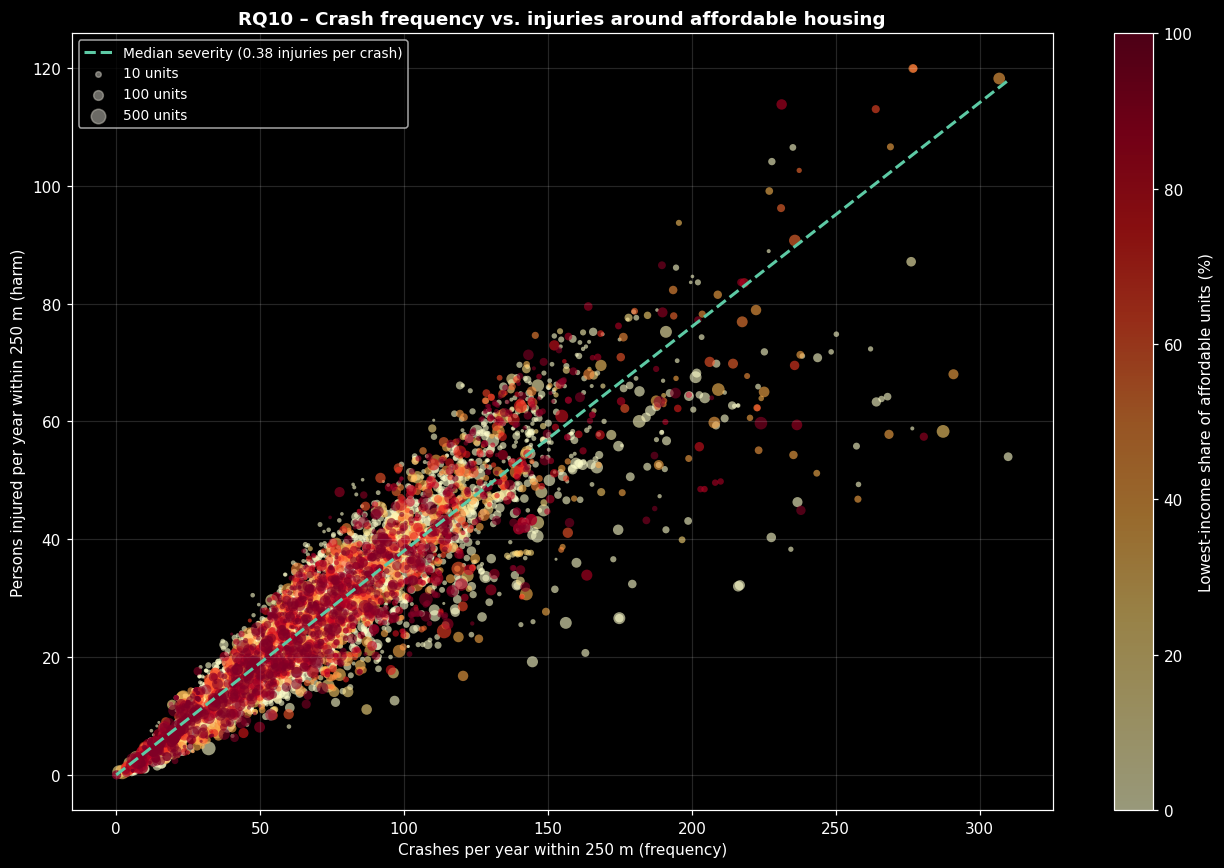

Above the dashed line = crashes are more injurious than at the typical site.


In [ ]:
# ---------- RQ10: crash frequency vs. harm around each building ----------
rq10 = sites[(sites['crashes_250m_per_year'] > 0)].dropna(subset=['lowest_income_share']).copy()
rq10['severity'] = rq10['injured_250m_per_year'] / rq10['crashes_250m_per_year']
rq10['lowest_income_group'] = pd.cut(rq10['lowest_income_share'], bins=[-0.001, 0, 0.25, 0.5, 1.0],
                                     labels=['None', 'Up to 25%', '25–50%', 'Over 50%'])
median_severity = rq10['severity'].median()

print(f'Median severity across all sites: {median_severity:.3f} injuries per crash\n')
print('Medians by lowest-income share:')
display(rq10.groupby('lowest_income_group', observed=True)
        .agg(sites=('severity', 'size'),
             crashes_per_year=('crashes_250m_per_year', 'median'),
             injured_per_year=('injured_250m_per_year', 'median'),
             severity=('severity', 'median'),
             above_median_severity_pct=('severity', lambda s: (s > median_severity).mean() * 100))
        .round(2))

# --- Bubble chart (Lectures 4–5) ---
rq10 = rq10.sort_values('lowest_income_share')        # draw high-share buildings on top
fig, ax = plt.subplots(figsize=(12, 8))
bubbles = ax.scatter(rq10['crashes_250m_per_year'], rq10['injured_250m_per_year'],
                     s=np.sqrt(rq10['all_counted_units']) * 4, c=rq10['lowest_income_share'] * 100,
                     cmap='YlOrRd', vmin=0, vmax=100, alpha=0.6, edgecolors='none')
xs = np.linspace(0, rq10['crashes_250m_per_year'].max(), 100)
ax.plot(xs, median_severity * xs, color='#5DCAA5', ls='--', lw=2,
        label=f'Median severity ({median_severity:.2f} injuries per crash)')
fig.colorbar(bubbles, ax=ax, label='Lowest-income share of affordable units (%)')

for units in [10, 100, 500]:                         # bubble-size legend
    ax.scatter([], [], s=np.sqrt(units) * 4, color='#B4B2A9', alpha=0.6, label=f'{units} units')
ax.set(title='RQ10 – Crash frequency vs. injuries around affordable housing',
       xlabel='Crashes per year within 250 m (frequency)',
       ylabel='Persons injured per year within 250 m (harm)')
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()
print('Above the dashed line = crashes are more injurious than at the typical site.')

## 10. Summary & Conclusions

### The one-sentence answer
**New York's affordable housing is concentrated in neighbourhoods that already have a lot of traffic injuries, but building it does not make those streets more dangerous, and the poorest households are not placed on worse streets than other affordable-housing residents.**

### Key findings

**1. The problem is at the neighbourhood level** (RQ3, RQ7)
- ZIPs that received more affordable housing rank much higher for traffic injuries (**r = 0.56**, the strongest result in the project). The 40 ZIPs with no affordable housing are among the safest in the city.
- **Manhattan (44.6%), Brooklyn (40.8%) and the Bronx (38.9%)** have the highest shares of affordable units in High / Very high danger areas.
- In Queens (20.9%) and Staten Island (0%) most units are on quiet streets.
- The danger clusters are the **South/Central Bronx, Upper Manhattan and Central/East Brooklyn**.

**2. Within affordable housing, danger is shared roughly equally across income groups** (RQ1, RQ5, RQ10)
- Median injuries near buildings with no lowest-income units and near buildings with over 50% lowest-income units differ by only **~5%**.
- Extremely-low-income units (42% in dangerous areas) and middle-income units (41%) have almost the same exposure.
- **Exception: the Bronx**, where buildings with mostly lowest-income units see **13% more injuries** nearby.
- Where lowest-income sites do face more danger, it comes from **more crashes, not more serious ones** (RQ10).

**3. New housing does not make streets more dangerous** (RQ2, RQ8, RQ9)
- After a building opens, nearby crash and injury changes match the city trend (group medians between –6% and +3%).
- A ZIP's injury ranking stays flat around its biggest wave of completions (median change **–0.01**).
- Over 2016–2025, the ZIPs that absorbed the **most** housing saw injuries fall the **most (–12.5%)**, compared with –1.4% in ZIPs with none.

**4. Where housing goes is slowly improving** (RQ4)
- The share of new units placed in dangerous areas fell from **43% (2016–2020)** to **37% (2021–2025)**.
- 2025 was the lowest year of the decade (31%).

**5. Pedestrians carry extra risk in the Bronx and Queens** (RQ6)
- Neighbourhoods there that receive new housing have a **4–5 percentage points higher pedestrian share** of injuries.

### What this means for NYC
1. **Plan street safety with housing, not after it.** New projects in the red clusters (Bronx, Upper Manhattan, Central Brooklyn) should come with a street-safety plan from day one. The streets are already dangerous before the building opens (RQ8).
2. **Pedestrian infrastructure first in the Bronx and Queens:** crossings, signal timing, sidewalk extensions (RQ6).
3. **Treat crash volume around lowest-income housing:** intersection redesign, loading zones and parking enforcement (RQ10). Speed measures should go to the small set of high-severity sites.
4. **Prioritise the Bronx.** It is the only borough where the poorest households are clearly more exposed (RQ1) and where the pedestrian gap is largest (RQ6).
5. **Keep the improving trend going** by continuing to steer new units away from High / Very high danger areas (RQ4).

### Limitations
- **No population or traffic-volume data:** denser ZIPs naturally have more housing *and* more crashes, so part of RQ7 is likely a density effect. Injuries are counted, not calculated per resident or per trip.
- **Correlation, not causation:** other changes (Vision Zero redesigns, COVID-19, enforcement) happened at the same time and cannot be separated out.
- **Only affordable housing:** the dataset has no market-rate buildings, so we compare affordable buildings with each other, not with all housing.
- **Spatial choices matter:** the 250 m radius picks up traffic on nearby major roads. The ZIP-level join hides differences inside a ZIP. Crash records with missing coordinates or ZIPs had to be dropped (Section 6).
- **Time:** "completion" is not the same as move-in. Danger levels describe 2016–2025 as a whole. The 2020 COVID year distorts year-to-year comparisons.

In [ ]:
# ---------- Website prep: inspect the final tables ----------
import os
import pandas as pd

for name in ['integrated_zip_year', 'building_exposure']:
    path = DATA_DIR + f'final/{name}.csv'
    df = pd.read_csv(path)
    print('=' * 90)
    print(f'{name}.csv  ->  {df.shape[0]:,} rows × {df.shape[1]} columns  |  {os.path.getsize(path) / 1e6:.1f} MB')
    print('=' * 90)
    print(df.dtypes.to_string(), '\n')

    print('Category values (text/bool columns with ≤ 15 distinct values):')
    for col in df.columns:
        if (df[col].dtype == 'object' or df[col].dtype == 'bool') and df[col].nunique() <= 15:
            print(f'  {col}: {sorted(df[col].dropna().astype(str).unique().tolist())}')
    for col in ['year', 'completion_year', 'project_completion_year']:
        if col in df.columns:
            print(f'  {col}: {int(df[col].min())} – {int(df[col].max())}')
    print()

integrated_zip_year.csv  ->  2,330 rows × 26 columns  |  0.2 MB
zip_code                            int64
year                                int64
borough                            object
crashes                             int64
injury_crashes                      int64
persons_injured                     int64
persons_killed                      int64
pedestrians_injured                 int64
pedestrians_killed                  int64
cyclists_injured                    int64
cyclists_killed                     int64
motorists_injured                   int64
motorists_killed                    int64
buildings_completed                 int64
units_completed                     int64
affordable_units_completed          int64
lowest_income_units_completed       int64
new_construction_buildings          int64
preservation_buildings              int64
affordable_units_cumulative         int64
lowest_income_units_cumulative      int64
is_special_zip                       bool
has_new_hous

## 11. Prompts & AI Use

We used **Claude (Anthropic)** as a coding and writing assistant. The team chose the datasets and questions, ran every cell, and checked all reported numbers against our own outputs.

| Stage | Example prompt |
|---|---|
| EDA & cleaning | "Write pandas code to profile missing values, outliers and duplicates in these columns." |
| Integration | "How should we join building data with crashes at ZIP × year and within 250 m?" |
| Findings | "Help phrase the findings for this chart output." |
| Website | "Build a Dash dashboard with these filters, a search box and a Generate Report button, and help deploy it on Render." |